China A-share monthly factor timing

We study one question: can machine learning improve a portfolio by changing the weights of Value, Profitability and Momentum each month? We keep the three factor definitions fixed. This follows our professor's advice to focus on factor timing. We compare fifteen models with equal factor weights and a historical-mean forecast. Each model also has a portfolio that keeps its first factor weights.

We use our group of 100 companies. Each factor buys the top 30% and shorts the bottom 30% of stocks with valid data. We use monthly decisions and daily prices. The same dates, trading rules and cost assumptions apply to every model. This is a historical research test. We have already studied these dates in our earlier work, so they are not a new unseen sample.

In [1]:
from pathlib import Path
import logging
import warnings
import math
import hashlib
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.dates import AutoDateLocator, ConciseDateFormatter
import torch
from torch import nn
from prophet import Prophet
from cmdstanpy.utils import get_logger as get_cmdstanpy_logger
from sklearn.linear_model import Ridge, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, AdaBoostRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import balanced_accuracy_score
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from IPython.display import display

We keep all 100 companies in the company table. We use the saved prices, annual accounts and share counts from our earlier work. A company needs enough price history and complete accounts before it can receive all three scores. We record the reason when it cannot be ranked.

In [2]:
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'inputs/china_factor_100').is_dir())
INPUTS = ROOT / 'inputs/china_factor_100'
RESULTS = ROOT / 'results/china_factor_timing_m6'
RESULTS.mkdir(parents=True, exist_ok=True)
pd.options.display.float_format = '{:,.3f}'.format
plt.rcParams.update({'figure.figsize': (11, 5), 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.2})
get_cmdstanpy_logger().setLevel(logging.WARNING)
logging.getLogger('prophet').setLevel(logging.WARNING)

# Read the same saved inputs for every model.
companies = pd.read_csv(INPUTS / 'stocks.csv', dtype={'code': str})
price_rows = pd.read_csv(INPUTS / 'prices.csv', dtype={'code': str}, parse_dates=['date'])
financials = pd.read_csv(INPUTS / 'financials.csv', dtype={'code': str}, parse_dates=['period', 'notice_date', 'available_date'])
share_rows = pd.read_csv(INPUTS / 'shares.csv', dtype={'code': str}, parse_dates=['effective_date', 'notice_date', 'available_date'])
companies['is_financial'] = companies.is_financial.astype(str).str.lower().isin(['true', '1', 'yes'])
financials['usable'] = financials.usable.astype(str).str.lower().isin(['true', '1', 'yes'])
financials['balance_usable'] = financials.balance_usable.astype(str).str.lower().isin(['true', '1', 'yes'])
STOCKS = companies.code.tolist()
if len(STOCKS) != 100 or len(set(STOCKS)) != 100:
    raise ValueError('We need 100 different six-digit company codes.')
if not companies.code.str.fullmatch(r'[0-9]{6}').all():
    raise ValueError('Check the stock codes.')
if price_rows.duplicated(['code', 'date']).any():
    raise ValueError('A stock has more than one price on the same date.')
if not set(price_rows.code).issubset(STOCKS):
    raise ValueError('A price belongs to a company outside the list.')
calendar = pd.DatetimeIndex(pd.read_csv(ROOT / 'inputs/china_benchmark/market_calendar.csv', parse_dates=['date']).date)
calendar = calendar[(calendar >= price_rows.date.min()) & (calendar <= price_rows.date.max())]
price_rows = price_rows.loc[price_rows.date.isin(calendar)].copy()
observed = price_rows.pivot(index='date', columns='code', values='adjusted_close').reindex(index=calendar, columns=STOCKS)
raw_observed = price_rows.pivot(index='date', columns='code', values='raw_close').reindex(index=calendar, columns=STOCKS)
volumes = price_rows.pivot(index='date', columns='code', values='volume').reindex(index=calendar, columns=STOCKS)
observed = observed.where(observed.gt(0))
raw_observed = raw_observed.where(raw_observed.gt(0))
tradable = observed.notna() & raw_observed.notna() & volumes.gt(0)
# Carry a last price only for valuation. A trade still needs a fresh quote.
prices = observed.ffill()
raw_prices = raw_observed.ffill()
first_quote_dates = {}
for stock in STOCKS:
    first_quote_dates[stock] = observed[stock].first_valid_index()
first_quotes = pd.Series(first_quote_dates)
first_quotes.index.name = observed.columns.name
finance_by_code = {stock: rows.sort_values(['period', 'available_date']) for stock, rows in financials.groupby('code')}
shares_by_code = {stock: rows.sort_values(['effective_date', 'available_date']) for stock, rows in share_rows.groupby('code')}
company_info = companies.set_index('code')
daily_returns = prices.pct_change(fill_method=None)
if observed.stack().le(0).any():
    raise ValueError('Prices must be positive.')
source_files = pd.DataFrame([{'file': file.name, 'sha256': hashlib.sha256(file.read_bytes()).hexdigest()} for file in INPUTS.glob('*.csv')])
source_files.to_csv(RESULTS / 'input_files.csv', index=False)
companies.to_csv(RESULTS / 'companies.csv', index=False)
display(companies[['code', 'name_en', 'name_zh', 'listing_date', 'is_financial']])

,code,name_en,name_zh,listing_date,is_financial
0,002371,"NAURA Technology Group Co.,Ltd.",北方華創,2010-03-16,False
1,002422,"Sichuan Kelun Pharmaceutical Co., Ltd.",科倫藥業,2010-06-03,False
2,601728,China Telecom Corporation Limited,中國電信,2021-08-20,False
3,600276,"Jiangsu Hengrui Pharmaceuticals Co.,Ltd.",恒瑞醫藥,2000-10-18,False
4,600519,"Kweichow Moutai Co.,Ltd.",貴州茅臺,2001-08-27,False
...,...,...,...,...,...
95,000338,"Weichai Power Co., Ltd.",濰柴動力,2007-04-30,False
96,688008,"Montage Technology Co., Ltd.",瀾起科技,2019-07-22,False
97,600150,China CSSC Holdings Limited,中國船舶,1998-05-20,False
98,601127,"Seres Group Co.,Ltd.",賽力斯,2016-06-15,False


We keep the factor definitions fixed. Value is EBIT divided by enterprise value. Profitability is EBIT divided by average invested capital. Momentum is the price return from twelve months ago to one month ago, divided by annual volatility. This leaves the last month out of the momentum return. Banks and insurance companies remain in our list, but they do not enter these EBIT baskets because their debt and capital have a different meaning.

In [3]:
FACTORS = ['Value', 'Profitability', 'Momentum']
MIN_ELIGIBLE = 12
MIN_QUOTE_COUNT = 160
STALE_REPORT_MONTHS = 18
TAIL_FRACTION = 0.30
SIDE_WEIGHT = 0.50

month_signals = calendar.to_series().groupby(calendar.to_period('M')).last()
month_signals = pd.DatetimeIndex(month_signals)
score_tables = {}
baskets = {}
all_score_rows = []
basket_rows = []
coverage_rows = []

for signal in month_signals:
    rows = []
    one_month = signal - pd.DateOffset(months=1)
    twelve_months = signal - pd.DateOffset(months=12)

    for stock in STOCKS:
        result = {
            'signal': signal,
            'code': stock,
            'eligible': False,
            'reason': '',
            'Value': np.nan,
            'Profitability': np.nan,
            'Momentum': np.nan,
        }

        if company_info.loc[stock, 'is_financial']:
            result['reason'] = 'Financial business'
        elif not bool(tradable.loc[signal, stock]):
            result['reason'] = 'No trading quote on the decision date'
        elif pd.isna(first_quotes[stock]) or first_quotes[stock] > twelve_months:
            result['reason'] = 'Less than twelve months of price history'
        else:
            accounts = finance_by_code.get(stock, pd.DataFrame())
            known_shares = shares_by_code.get(stock, pd.DataFrame())

            if len(accounts):
                accounts = accounts.loc[accounts.available_date.le(signal)]
                accounts = accounts.sort_values(['period', 'available_date'])
                accounts = accounts.drop_duplicates('period', keep='last')
            if len(known_shares):
                known_shares = known_shares.loc[
                    known_shares.available_date.le(signal)
                    & known_shares.effective_date.le(signal)
                ]

            if accounts.empty:
                result['reason'] = 'No available annual accounts'
            elif known_shares.empty:
                result['reason'] = 'No available total share count'
            else:
                current = accounts.iloc[-1]
                prior = accounts.loc[accounts.period.eq(current.period - pd.DateOffset(years=1))]

                if not bool(current.usable):
                    result['reason'] = 'Incomplete EBIT or capital fields'
                elif prior.empty or not bool(prior.iloc[-1].balance_usable):
                    result['reason'] = 'No complete opening capital'
                elif signal > current.period + pd.DateOffset(months=STALE_REPORT_MONTHS):
                    result['reason'] = 'Annual accounts are more than eighteen months old'
                else:
                    opening = prior.iloc[-1]
                    shares = known_shares.iloc[-1]
                    market_cap = float(raw_prices.loc[signal, stock]) * float(shares.total_shares)
                    enterprise_value = market_cap + current.interest_debt + current.minority_equity - current.cash
                    average_capital = (current.invested_capital + opening.invested_capital) / 2
                    history = daily_returns.loc[twelve_months:signal, stock].dropna()
                    quote_count = int(tradable.loc[twelve_months:signal, stock].sum())
                    volatility = history.std(ddof=1) * np.sqrt(252)
                    one_month_prices = prices.loc[:one_month, stock]
                    twelve_month_prices = prices.loc[:twelve_months, stock]
                    one_month_close = float(one_month_prices.iloc[-1]) if len(one_month_prices) else np.nan
                    twelve_month_close = float(twelve_month_prices.iloc[-1]) if len(twelve_month_prices) else np.nan
                    momentum = one_month_close / twelve_month_close - 1
                    values = [current.ebit, enterprise_value, average_capital, market_cap, volatility, momentum]

                    if not np.isfinite(values).all() or min(enterprise_value, average_capital, market_cap, volatility) <= 0:
                        result['reason'] = 'Invalid factor denominator'
                    elif quote_count < MIN_QUOTE_COUNT:
                        result['reason'] = 'Too few daily trading quotes for momentum'
                    else:
                        result.update({
                            'eligible': True,
                            'reason': 'Available',
                            'Value': current.ebit / enterprise_value,
                            'Profitability': current.ebit / average_capital,
                            'Momentum': momentum / volatility,
                            'period': current.period,
                            'available_date': current.available_date,
                            'opening_available_date': opening.available_date,
                            'share_available_date': shares.available_date,
                            'share_effective_date': shares.effective_date,
                            'ebit': current.ebit,
                            'enterprise_value': enterprise_value,
                            'average_capital': average_capital,
                            'market_cap': market_cap,
                            'volatility': volatility,
                        })

        rows.append(result)

    scores = pd.DataFrame(rows).set_index('code')
    all_score_rows.append(scores.reset_index())
    if len(scores) != 100 or set(scores.index) != set(STOCKS):
        raise ValueError('Every monthly table must contain all 100 companies.')
    eligible = scores.loc[scores.eligible].sort_index()

    if len(eligible) >= MIN_ELIGIBLE:
        score_tables[signal] = scores
        count = int(math.floor(len(eligible) * TAIL_FRACTION))
        weights = pd.DataFrame(0.0, index=STOCKS, columns=FACTORS)
        for factor in FACTORS:
            ranked = eligible[factor].sort_values(ascending=False, kind='stable')
            long_codes = ranked.head(count).index
            short_codes = ranked.tail(count).index
            if set(long_codes).intersection(short_codes):
                raise ValueError('The long and short sides overlap.')
            weights.loc[long_codes, factor] = SIDE_WEIGHT / count
            weights.loc[short_codes, factor] = -SIDE_WEIGHT / count
            if not np.isclose(weights[factor].sum(), 0) or not np.isclose(weights[factor].abs().sum(), 1):
                raise ValueError('Each basket must have zero net and one unit of gross exposure.')
            for code in long_codes:
                basket_rows.append({'signal': signal, 'factor': factor, 'code': code, 'side': 'Long', 'weight': weights.loc[code, factor]})
            for code in short_codes:
                basket_rows.append({'signal': signal, 'factor': factor, 'code': code, 'side': 'Short', 'weight': weights.loc[code, factor]})
        baskets[signal] = weights
        coverage_rows.append({'signal': signal, 'listed_companies': len(STOCKS), 'eligible_companies': len(eligible), 'long_count': count, 'short_count': count, 'eligible_not_held_per_factor': len(eligible) - 2 * count, 'excluded_companies': len(STOCKS) - len(eligible)})

score_history = pd.concat(all_score_rows, ignore_index=True)
score_history.to_csv(RESULTS / 'factor_scores.csv', index=False)
eligible_counts = score_history.groupby('signal').eligible.sum().rename('eligible_count')
eligible_counts.to_csv(RESULTS / 'eligible_counts.csv')
pd.DataFrame(basket_rows).to_csv(RESULTS / 'factor_baskets.csv', index=False)
monthly_coverage = pd.DataFrame(coverage_rows).set_index('signal')
monthly_coverage.to_csv(RESULTS / 'monthly_coverage.csv')
exclusion_reasons = score_history.loc[~score_history.eligible].groupby(['signal', 'reason']).size().rename('companies').reset_index()
exclusion_reasons.to_csv(RESULTS / 'exclusion_reasons.csv', index=False)

if not baskets:
    raise ValueError('No month has enough complete company data.')

used = score_history.loc[score_history.eligible]
for field in ['available_date', 'opening_available_date', 'share_available_date', 'share_effective_date']:
    if not used[field].le(used.signal).all():
        raise ValueError('A factor score uses information from after its decision date.')

display(monthly_coverage.tail(6))
display(score_tables[max(score_tables)].query('eligible')[FACTORS].head(10))

,listed_companies,eligible_companies,long_count,short_count,eligible_not_held_per_factor,excluded_companies
signal,,,,,,
2026-05-29,100,93,27,27,39,7
2026-06-30,100,94,28,28,38,6
2026-07-31,100,94,28,28,38,6
2026-08-31,100,94,28,28,38,6
2026-09-30,100,94,28,28,38,6
2026-10-16,100,94,28,28,38,6


,Value,Profitability,Momentum
code,,,
002371,0.014,0.180,1.245
002422,0.038,0.093,0.374
601728,0.077,0.107,-0.197
600276,0.032,0.412,-1.071
600519,0.070,0.539,-0.544
688981,0.010,0.038,-0.095
300760,0.051,0.387,-1.172
688271,0.024,0.136,-1.029
688111,0.018,0.171,-0.614


For each factor, we buy the top 30% and short the bottom 30% of companies with valid scores. We round each group down to a whole number. The long side is +50% of the basket value and the short side is -50%. Companies have equal weights within each side. All three factors use the same eligible group each month. The basket returns used as model targets do not include trading fees or borrowing costs. We include these costs later when we compare the allocation rules.

In [4]:
INITIAL_VALUE = 100000.0
LONG_SHARE = 0.50
SHORT_SHARE = 0.50

entries = {}
for signal in score_tables:
    position = calendar.searchsorted(signal, side='right')
    if position < len(calendar):
        entries[signal] = calendar[position]

first_entry = min(entries.values())
first_position = calendar.get_loc(first_entry)
base_date = calendar[first_position - 1] if first_position > 0 else first_entry
factor_dates = calendar[(calendar >= base_date) & (calendar <= calendar[-1])]
factor_curves = {}
factor_exposure_rows = []

for factor in FACTORS:
    schedule = {}
    for signal, entry in entries.items():
        schedule[entry] = baskets[signal][factor].reindex(STOCKS, fill_value=0).to_numpy(float)

    holdings = np.zeros(len(STOCKS))
    cash = INITIAL_VALUE
    values = []
    previous = None

    for day in factor_dates:
        if previous is not None:
            relative = prices.loc[day].to_numpy(float) / prices.loc[previous].to_numpy(float)
            if not np.isfinite(relative[np.abs(holdings) > 1e-10]).all():
                raise ValueError('A held stock has no valuation price.')
            holdings *= np.where(np.isfinite(relative), relative, 1.0)

        before = cash + holdings.sum()
        if before <= 0 or not np.isfinite(before):
            raise ValueError('A factor basket has no positive capital left.')

        if day in schedule:
            target = schedule[day]
            can_trade = tradable.loc[day].to_numpy(bool)
            frozen = holdings[~can_trade]
            frozen_long = frozen[frozen > 0].sum()
            frozen_short = -frozen[frozen < 0].sum()
            long_budget = max(LONG_SHARE * before - frozen_long, 0.0)
            short_budget = max(SHORT_SHARE * before - frozen_short, 0.0)
            long_target = np.clip(target[can_trade], 0, None)
            short_target = np.clip(-target[can_trade], 0, None)

            # A suspended holding stays in place until it can trade again.
            holdings[can_trade] = 0.0
            if long_target.sum() > 0:
                holdings[can_trade] += long_budget * long_target / long_target.sum()
            if short_target.sum() > 0:
                holdings[can_trade] -= short_budget * short_target / short_target.sum()
            cash = before - holdings.sum()

            long_value = holdings[holdings > 0].sum()
            short_value = -holdings[holdings < 0].sum()
            balanced = np.isclose(long_value, LONG_SHARE * before) and np.isclose(short_value, SHORT_SHARE * before)
            if frozen_long <= LONG_SHARE * before and frozen_short <= SHORT_SHARE * before and long_target.sum() > 0 and short_target.sum() > 0 and not balanced:
                raise ValueError('The two sides do not match their planned exposure.')
            factor_exposure_rows.append({
                'factor': factor, 'date': day, 'value': before,
                'long_exposure': long_value / before,
                'short_exposure': -short_value / before,
                'gross_exposure': (long_value + short_value) / before,
                'net_exposure': (long_value - short_value) / before,
                'frozen_long': frozen_long / before,
                'frozen_short': frozen_short / before,
                'unavailable_long_targets': int(((target > 0) & ~can_trade).sum()),
                'unavailable_short_targets': int(((target < 0) & ~can_trade).sum()),
                'balanced': balanced,
            })

        value = cash + holdings.sum()
        if value <= 0 or not np.isfinite(value):
            raise ValueError('The factor value is invalid.')
        values.append({'date': day, 'value': value, 'cash': cash})
        previous = day

    curve = pd.DataFrame(values).set_index('date')
    factor_curves[factor] = curve.value

factor_values = pd.DataFrame(factor_curves)
factor_values.to_csv(RESULTS / 'factor_history.csv')
factor_exposure = pd.DataFrame(factor_exposure_rows)
factor_exposure.to_csv(RESULTS / 'factor_exposures.csv', index=False)

monthly_rows = []
signals = sorted(entries)
for signal, following in zip(signals[:-1], signals[1:]):
    if following.to_period('M') != signal.to_period('M') + 1:
        continue
    entry = entries[signal]
    exit_date = entries[following]
    outcome = factor_values.loc[exit_date] / factor_values.loc[entry] - 1
    monthly_rows.append({'signal': signal, 'entry': entry, 'exit': exit_date, **outcome.to_dict()})

factor_targets = pd.DataFrame(monthly_rows).set_index('signal')
factor_targets.to_csv(RESULTS / 'factor_targets.csv')
display(factor_targets.tail(6))
display(factor_exposure.groupby('factor')[['gross_exposure', 'net_exposure']].agg(['min', 'max']))

,entry,exit,Value,Profitability,Momentum
signal,,,,,
2026-03-31,2026-04-01,2026-05-06,-0.087,0.017,0.079
2026-04-30,2026-05-06,2026-06-01,-0.016,0.030,-0.001
2026-05-29,2026-06-01,2026-07-01,-0.086,0.018,0.023
2026-06-30,2026-07-01,2026-08-03,0.131,-0.008,-0.102
2026-07-31,2026-08-03,2026-09-01,-0.012,0.008,0.023
2026-08-31,2026-09-01,2026-10-08,0.023,-0.012,-0.023


gross_exposure       net_exposure      
                         min   max          min   max
factor                                               
Momentum               1.000 1.000       -0.000 0.000
Profitability          1.000 1.000       -0.000 0.000
Value                  1.000 1.000       -0.000 0.000

We decide after the last trading close of the month and trade at the next trading close. The long-short basket is a research simulation. It assumes that selected short positions can be borrowed. A missing quote does not create a trade. We keep an existing position at its last available price until a new quote arrives, and record any exposure difference caused by this rule. Cash earns zero interest in this test.

In [5]:
LOOKBACK = 8
RETURN_WINDOWS = (1, 4, 13)
RISK_WINDOW = 13
MIN_TRAINING = 36
VALIDATION_START = pd.Timestamp('2023-01-01')
VALIDATION_END = pd.Timestamp('2024-12-31')
TEST_START = pd.Timestamp('2025-01-01')
TEST_END = pd.Timestamp('2026-10-08')

sequences = {}
sequence_rows = []
sequence_date_rows = []

for signal in factor_targets.index:
    history = factor_values.loc[:signal]
    weekly = history.groupby(history.index.to_period('W-FRI')).tail(1)
    if len(weekly) < LOOKBACK + max(max(RETURN_WINDOWS), RISK_WINDOW):
        continue

    changes = weekly.pct_change(fill_method=None)
    rows = []
    for index in range(len(weekly) - LOOKBACK, len(weekly)):
        values = {}
        risk_returns = changes.iloc[index - RISK_WINDOW + 1:index + 1]
        for factor in FACTORS:
            for window in RETURN_WINDOWS:
                values[f'{factor}_{window}w'] = weekly[factor].iloc[index] / weekly[factor].iloc[index - window] - 1
            values[f'{factor}_volatility'] = risk_returns[factor].std(ddof=1) * np.sqrt(52)

        correlations = risk_returns.corr().to_numpy()[np.triu_indices(3, 1)]
        values['factor_correlation'] = float(correlations.mean())
        rows.append(values)

    frame = pd.DataFrame(rows, index=weekly.tail(LOOKBACK).index)
    if not np.isfinite(frame.to_numpy()).all():
        continue

    sequences[signal] = frame.to_numpy()
    sequence_rows.append(frame.assign(signal=signal).rename_axis('week').reset_index())
    sequence_date_rows.append({
        'signal': signal,
        'first_input_week': frame.index.min(),
        'last_input_week': frame.index.max(),
    })

sequence_dates = pd.DataFrame(sequence_date_rows).set_index('signal')
sample_signals = pd.DatetimeIndex(sorted(sequences))
samples = factor_targets.loc[sample_signals]
sample_x = np.stack([sequences[signal] for signal in sample_signals])
sample_y = samples[FACTORS].to_numpy()
pd.concat(sequence_rows, ignore_index=True).to_csv(RESULTS / 'sequence_inputs.csv', index=False)

validation_signals = samples.index[samples.entry.ge(VALIDATION_START) & samples.exit.le(VALIDATION_END)]
test_signals = samples.index[samples.entry.ge(TEST_START) & samples.exit.le(TEST_END)]
run_signals = validation_signals.append(test_signals)

if len(validation_signals) != 23 or len(test_signals) != 21:
    raise ValueError('We need 23 validation months and 21 completed evaluation months.')
if samples.loc[validation_signals].exit.max() > test_signals.min():
    raise ValueError('Model selection finishes after the first evaluation decision.')
for signal in run_signals:
    count = int(samples.exit.le(signal).sum())
    if count < MIN_TRAINING:
        raise ValueError(f'Only {count} completed training months before {signal.date()}.')

period_table = pd.DataFrame([
    {
        'part': 'Validation',
        'first_entry': samples.loc[validation_signals].entry.min(),
        'last_exit': samples.loc[validation_signals].exit.max(),
        'months': len(validation_signals),
    },
    {
        'part': 'Evaluation',
        'first_entry': samples.loc[test_signals].entry.min(),
        'last_exit': samples.loc[test_signals].exit.max(),
        'months': len(test_signals),
    },
])
period_table.to_csv(RESULTS / 'periods.csv', index=False)
display(period_table)
display(monthly_coverage.loc[run_signals].agg(['min', 'max']))
if not sequence_dates.last_input_week.le(sequence_dates.index).all():
    raise ValueError('An input uses a week after the forecast decision.')
sequence_dates.to_csv(RESULTS / 'sequence_dates.csv')


,part,first_entry,last_exit,months
0,Validation,2023-01-03,2024-12-02,23
1,Evaluation,2025-01-02,2026-10-08,21


,listed_companies,eligible_companies,long_count,short_count,eligible_not_held_per_factor,excluded_companies
min,100,90,27,27,36,6
max,100,94,28,28,39,10


We have 93 usable monthly samples. The first factor trade is on 1 August 2018. Earlier prices are available, but most earlier accounts do not have the financing-interest figures needed for EBIT. We do not fill these missing figures with zero. During the later comparison, 90 to 94 of our 100 companies have all three scores. Each factor therefore holds 27 or 28 companies on each side. All models use the same 23 validation periods and 21 later periods.

Each input contains eight observed weeks. In each week we calculate one-, four- and thirteen-week returns for the three factors, thirteen-week volatility, and their average correlation. This gives thirteen values per week. We compare models with these same inputs. The training sample grows over time. A monthly outcome enters training only after its holding period has finished. We keep dates in order so that a forecast cannot learn from a later outcome.

We forecast the next monthly return of each long-short factor basket. We use the same completed months for every model. The inputs stop at the decision date. We do not shuffle the months because later prices must not enter an earlier forecast. We keep the random seed fixed so we can repeat the reported run. The settings appear at the start of each model cell.

In [6]:
LEARNED_MODELS = ['Ridge', 'Elastic Net', 'KNN', 'SVR', 'Random Forest', 'Extra Trees', 'XGBoost', 'Decision Tree', 'AdaBoost', 'LightGBM', 'MLP', 'LSTM', 'GRU', 'CNN', 'Prophet']
MODEL_FILES = RESULTS / 'model_outputs'
MODEL_FILES.mkdir(parents=True, exist_ok=True)
model_audits = []
history_rows = []
training_rows = []

for signal in run_signals:
    training_mask = samples.exit.le(signal).to_numpy()
    training_index = sample_signals[training_mask]
    position = sample_signals.get_loc(signal)
    split = 'validation' if signal in validation_signals else 'evaluation'
    if len(training_index) < MIN_TRAINING:
        raise ValueError('Too few completed training months.')
    forecast = sample_y[training_mask].mean(axis=0)
    training_rows.append({
        'signal': signal,
        'split': split,
        'training_months': len(training_index),
        'first_training_signal': training_index[0],
        'last_training_exit': samples.loc[training_index, 'exit'].max(),
        'first_input_week': sequence_dates.loc[signal, 'first_input_week'],
        'last_input_week': sequence_dates.loc[signal, 'last_input_week'],
    })
    for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
        history_rows.append({
            'signal': signal, 'entry': samples.loc[signal, 'entry'],
            'exit': samples.loc[signal, 'exit'], 'split': split,
            'model': 'Historical mean', 'factor': factor,
            'predicted_return': value, 'actual_return': actual,
        })

history_predictions = pd.DataFrame(history_rows)
training_audit = pd.DataFrame(training_rows)
training_audit.to_csv(RESULTS / 'training_dates.csv', index=False)
if not training_audit.last_training_exit.le(training_audit.signal).all():
    raise ValueError('Training includes a return that was not finished.')
if not training_audit.last_input_week.le(training_audit.signal).all():
    raise ValueError('Inputs include a future date.')
print('Historical mean:', len(history_predictions) // 3, 'monthly forecasts')
history_predictions.to_csv(MODEL_FILES / 'historical_mean_predictions.csv', index=False)
history_audit = training_audit.assign(model='Historical mean')
history_audit.to_csv(MODEL_FILES / 'historical_mean_audit.csv', index=False)
model_audits.append(history_audit)


Historical mean: 44 monthly forecasts


Ridge is our linear model. Its penalty reduces large coefficients.

In [7]:
alpha = 10.0
ridge_rows = []
ridge_warnings = []

for signal in run_signals:
    # Only completed past returns enter this fit.
    training_mask = samples.exit.le(signal).to_numpy()
    position = sample_signals.get_loc(signal)
    train_x = sample_x[training_mask].reshape(training_mask.sum(), -1)
    train_y = sample_y[training_mask]
    test_x = sample_x[position:position + 1].reshape(1, -1)
    split = 'validation' if signal in validation_signals else 'evaluation'
    feature_scaler = StandardScaler().fit(train_x)
    target_scaler = StandardScaler().fit(train_y)
    fitting_x = feature_scaler.transform(train_x)
    fitting_y = target_scaler.transform(train_y)
    prediction_x = feature_scaler.transform(test_x)
    model = Ridge(alpha=alpha)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        model.fit(fitting_x, fitting_y)
        forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
    for warning in caught:
        ridge_warnings.append({'signal': signal, 'model': 'Ridge', 'message': str(warning.message)})
    forecast = target_scaler.inverse_transform(forecast)
    forecast = forecast[0]
    if not np.isfinite(forecast).all():
        raise ValueError('Ridge produced an invalid forecast.')
    for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
        ridge_rows.append({
            'signal': signal, 'entry': samples.loc[signal, 'entry'],
            'exit': samples.loc[signal, 'exit'], 'split': split,
            'model': 'Ridge', 'factor': factor,
            'predicted_return': value, 'actual_return': actual,
        })

ridge_predictions = pd.DataFrame(ridge_rows)
print('Ridge:', len(ridge_predictions) // 3, 'monthly forecasts')
ridge_predictions.to_csv(MODEL_FILES / 'ridge_predictions.csv', index=False)
pd.DataFrame(ridge_warnings, columns=['signal', 'model', 'message']).to_csv(MODEL_FILES / 'ridge_warnings.csv', index=False)
ridge_audit = training_audit.assign(model='Ridge')
ridge_audit.to_csv(MODEL_FILES / 'ridge_audit.csv', index=False)
model_audits.append(ridge_audit)


Ridge: 44 monthly forecasts


Elastic Net is a linear model with two penalties. It can reduce some coefficients to zero.

In [8]:
alpha = 0.02
l1_ratio = 0.5
max_iterations = 10000
seed = 42
elastic_net_rows = []
elastic_net_warnings = []

for signal in run_signals:
    # Only completed past returns enter this fit.
    training_mask = samples.exit.le(signal).to_numpy()
    position = sample_signals.get_loc(signal)
    train_x = sample_x[training_mask].reshape(training_mask.sum(), -1)
    train_y = sample_y[training_mask]
    test_x = sample_x[position:position + 1].reshape(1, -1)
    split = 'validation' if signal in validation_signals else 'evaluation'
    feature_scaler = StandardScaler().fit(train_x)
    target_scaler = StandardScaler().fit(train_y)
    fitting_x = feature_scaler.transform(train_x)
    fitting_y = target_scaler.transform(train_y)
    prediction_x = feature_scaler.transform(test_x)
    model = MultiOutputRegressor(ElasticNet(alpha=alpha, l1_ratio=l1_ratio, max_iter=max_iterations, random_state=seed))
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        model.fit(fitting_x, fitting_y)
        forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
    for warning in caught:
        elastic_net_warnings.append({'signal': signal, 'model': 'Elastic Net', 'message': str(warning.message)})
    forecast = target_scaler.inverse_transform(forecast)
    forecast = forecast[0]
    if not np.isfinite(forecast).all():
        raise ValueError('Elastic Net produced an invalid forecast.')
    for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
        elastic_net_rows.append({
            'signal': signal, 'entry': samples.loc[signal, 'entry'],
            'exit': samples.loc[signal, 'exit'], 'split': split,
            'model': 'Elastic Net', 'factor': factor,
            'predicted_return': value, 'actual_return': actual,
        })

elastic_net_predictions = pd.DataFrame(elastic_net_rows)
print('Elastic Net:', len(elastic_net_predictions) // 3, 'monthly forecasts')
elastic_net_predictions.to_csv(MODEL_FILES / 'elastic_net_predictions.csv', index=False)
pd.DataFrame(elastic_net_warnings, columns=['signal', 'model', 'message']).to_csv(MODEL_FILES / 'elastic_net_warnings.csv', index=False)
elastic_net_audit = training_audit.assign(model='Elastic Net')
elastic_net_audit.to_csv(MODEL_FILES / 'elastic_net_audit.csv', index=False)
model_audits.append(elastic_net_audit)


Elastic Net: 44 monthly forecasts


KNN uses twenty similar past samples to make a forecast.

In [9]:
neighbours = 20
knn_rows = []
knn_warnings = []

for signal in run_signals:
    # Only completed past returns enter this fit.
    training_mask = samples.exit.le(signal).to_numpy()
    position = sample_signals.get_loc(signal)
    train_x = sample_x[training_mask].reshape(training_mask.sum(), -1)
    train_y = sample_y[training_mask]
    test_x = sample_x[position:position + 1].reshape(1, -1)
    split = 'validation' if signal in validation_signals else 'evaluation'
    feature_scaler = StandardScaler().fit(train_x)
    target_scaler = StandardScaler().fit(train_y)
    fitting_x = feature_scaler.transform(train_x)
    fitting_y = target_scaler.transform(train_y)
    prediction_x = feature_scaler.transform(test_x)
    model = KNeighborsRegressor(n_neighbors=neighbours)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        model.fit(fitting_x, fitting_y)
        forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
    for warning in caught:
        knn_warnings.append({'signal': signal, 'model': 'KNN', 'message': str(warning.message)})
    forecast = target_scaler.inverse_transform(forecast)
    forecast = forecast[0]
    if not np.isfinite(forecast).all():
        raise ValueError('KNN produced an invalid forecast.')
    for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
        knn_rows.append({
            'signal': signal, 'entry': samples.loc[signal, 'entry'],
            'exit': samples.loc[signal, 'exit'], 'split': split,
            'model': 'KNN', 'factor': factor,
            'predicted_return': value, 'actual_return': actual,
        })

knn_predictions = pd.DataFrame(knn_rows)
print('KNN:', len(knn_predictions) // 3, 'monthly forecasts')
knn_predictions.to_csv(MODEL_FILES / 'knn_predictions.csv', index=False)
pd.DataFrame(knn_warnings, columns=['signal', 'model', 'message']).to_csv(MODEL_FILES / 'knn_warnings.csv', index=False)
knn_audit = training_audit.assign(model='KNN')
knn_audit.to_csv(MODEL_FILES / 'knn_audit.csv', index=False)
model_audits.append(knn_audit)


KNN: 44 monthly forecasts


SVR uses an RBF kernel. We fit a separate model for each factor.

In [10]:
regularization = 1.0
epsilon = 0.1
svr_rows = []
svr_warnings = []

for signal in run_signals:
    # Only completed past returns enter this fit.
    training_mask = samples.exit.le(signal).to_numpy()
    position = sample_signals.get_loc(signal)
    train_x = sample_x[training_mask].reshape(training_mask.sum(), -1)
    train_y = sample_y[training_mask]
    test_x = sample_x[position:position + 1].reshape(1, -1)
    split = 'validation' if signal in validation_signals else 'evaluation'
    feature_scaler = StandardScaler().fit(train_x)
    target_scaler = StandardScaler().fit(train_y)
    fitting_x = feature_scaler.transform(train_x)
    fitting_y = target_scaler.transform(train_y)
    prediction_x = feature_scaler.transform(test_x)
    model = MultiOutputRegressor(SVR(C=regularization, epsilon=epsilon, kernel='rbf'))
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        model.fit(fitting_x, fitting_y)
        forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
    for warning in caught:
        svr_warnings.append({'signal': signal, 'model': 'SVR', 'message': str(warning.message)})
    forecast = target_scaler.inverse_transform(forecast)
    forecast = forecast[0]
    if not np.isfinite(forecast).all():
        raise ValueError('SVR produced an invalid forecast.')
    for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
        svr_rows.append({
            'signal': signal, 'entry': samples.loc[signal, 'entry'],
            'exit': samples.loc[signal, 'exit'], 'split': split,
            'model': 'SVR', 'factor': factor,
            'predicted_return': value, 'actual_return': actual,
        })

svr_predictions = pd.DataFrame(svr_rows)
print('SVR:', len(svr_predictions) // 3, 'monthly forecasts')
svr_predictions.to_csv(MODEL_FILES / 'svr_predictions.csv', index=False)
pd.DataFrame(svr_warnings, columns=['signal', 'model', 'message']).to_csv(MODEL_FILES / 'svr_warnings.csv', index=False)
svr_audit = training_audit.assign(model='SVR')
svr_audit.to_csv(MODEL_FILES / 'svr_audit.csv', index=False)
model_audits.append(svr_audit)


SVR: 44 monthly forecasts


Random Forest averages 150 trees. The depth and minimum leaf size limit each tree.

In [11]:
trees = 150
max_depth = 4
min_leaf = 12
seed = 42
random_forest_rows = []
random_forest_warnings = []

for signal in run_signals:
    # Only completed past returns enter this fit.
    training_mask = samples.exit.le(signal).to_numpy()
    position = sample_signals.get_loc(signal)
    train_x = sample_x[training_mask].reshape(training_mask.sum(), -1)
    train_y = sample_y[training_mask]
    test_x = sample_x[position:position + 1].reshape(1, -1)
    split = 'validation' if signal in validation_signals else 'evaluation'
    fitting_x = train_x
    fitting_y = train_y
    prediction_x = test_x
    model = RandomForestRegressor(n_estimators=trees, max_depth=max_depth, min_samples_leaf=min_leaf, random_state=seed, n_jobs=2)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        model.fit(fitting_x, fitting_y)
        forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
    for warning in caught:
        random_forest_warnings.append({'signal': signal, 'model': 'Random Forest', 'message': str(warning.message)})
    forecast = forecast[0]
    if not np.isfinite(forecast).all():
        raise ValueError('Random Forest produced an invalid forecast.')
    for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
        random_forest_rows.append({
            'signal': signal, 'entry': samples.loc[signal, 'entry'],
            'exit': samples.loc[signal, 'exit'], 'split': split,
            'model': 'Random Forest', 'factor': factor,
            'predicted_return': value, 'actual_return': actual,
        })

random_forest_predictions = pd.DataFrame(random_forest_rows)
print('Random Forest:', len(random_forest_predictions) // 3, 'monthly forecasts')
random_forest_predictions.to_csv(MODEL_FILES / 'random_forest_predictions.csv', index=False)
pd.DataFrame(random_forest_warnings, columns=['signal', 'model', 'message']).to_csv(MODEL_FILES / 'random_forest_warnings.csv', index=False)
random_forest_audit = training_audit.assign(model='Random Forest')
random_forest_audit.to_csv(MODEL_FILES / 'random_forest_audit.csv', index=False)
model_audits.append(random_forest_audit)


Random Forest: 44 monthly forecasts


Extra Trees also averages trees. It makes more random choices when it divides the inputs.

In [12]:
trees = 150
max_depth = 4
min_leaf = 12
seed = 42
extra_trees_rows = []
extra_trees_warnings = []

for signal in run_signals:
    # Only completed past returns enter this fit.
    training_mask = samples.exit.le(signal).to_numpy()
    position = sample_signals.get_loc(signal)
    train_x = sample_x[training_mask].reshape(training_mask.sum(), -1)
    train_y = sample_y[training_mask]
    test_x = sample_x[position:position + 1].reshape(1, -1)
    split = 'validation' if signal in validation_signals else 'evaluation'
    fitting_x = train_x
    fitting_y = train_y
    prediction_x = test_x
    model = ExtraTreesRegressor(n_estimators=trees, max_depth=max_depth, min_samples_leaf=min_leaf, random_state=seed, n_jobs=2)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        model.fit(fitting_x, fitting_y)
        forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
    for warning in caught:
        extra_trees_warnings.append({'signal': signal, 'model': 'Extra Trees', 'message': str(warning.message)})
    forecast = forecast[0]
    if not np.isfinite(forecast).all():
        raise ValueError('Extra Trees produced an invalid forecast.')
    for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
        extra_trees_rows.append({
            'signal': signal, 'entry': samples.loc[signal, 'entry'],
            'exit': samples.loc[signal, 'exit'], 'split': split,
            'model': 'Extra Trees', 'factor': factor,
            'predicted_return': value, 'actual_return': actual,
        })

extra_trees_predictions = pd.DataFrame(extra_trees_rows)
print('Extra Trees:', len(extra_trees_predictions) // 3, 'monthly forecasts')
extra_trees_predictions.to_csv(MODEL_FILES / 'extra_trees_predictions.csv', index=False)
pd.DataFrame(extra_trees_warnings, columns=['signal', 'model', 'message']).to_csv(MODEL_FILES / 'extra_trees_warnings.csv', index=False)
extra_trees_audit = training_audit.assign(model='Extra Trees')
extra_trees_audit.to_csv(MODEL_FILES / 'extra_trees_audit.csv', index=False)
model_audits.append(extra_trees_audit)


Extra Trees: 44 monthly forecasts


XGBoost adds small trees one after another. Each new tree tries to reduce the remaining error.

In [13]:
trees = 120
max_depth = 2
learning_rate = 0.03
subsample = 0.8
column_sample = 0.9
l2_penalty = 5.0
seed = 42
xgboost_rows = []
xgboost_warnings = []

for signal in run_signals:
    # Only completed past returns enter this fit.
    training_mask = samples.exit.le(signal).to_numpy()
    position = sample_signals.get_loc(signal)
    train_x = sample_x[training_mask].reshape(training_mask.sum(), -1)
    train_y = sample_y[training_mask]
    test_x = sample_x[position:position + 1].reshape(1, -1)
    split = 'validation' if signal in validation_signals else 'evaluation'
    fitting_x = train_x
    fitting_y = train_y
    prediction_x = test_x
    model = MultiOutputRegressor(XGBRegressor(n_estimators=trees, max_depth=max_depth, learning_rate=learning_rate, subsample=subsample, colsample_bytree=column_sample, reg_lambda=l2_penalty, objective='reg:squarederror', random_state=seed, n_jobs=2))
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        model.fit(fitting_x, fitting_y)
        forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
    for warning in caught:
        xgboost_warnings.append({'signal': signal, 'model': 'XGBoost', 'message': str(warning.message)})
    forecast = forecast[0]
    if not np.isfinite(forecast).all():
        raise ValueError('XGBoost produced an invalid forecast.')
    for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
        xgboost_rows.append({
            'signal': signal, 'entry': samples.loc[signal, 'entry'],
            'exit': samples.loc[signal, 'exit'], 'split': split,
            'model': 'XGBoost', 'factor': factor,
            'predicted_return': value, 'actual_return': actual,
        })

xgboost_predictions = pd.DataFrame(xgboost_rows)
print('XGBoost:', len(xgboost_predictions) // 3, 'monthly forecasts')
xgboost_predictions.to_csv(MODEL_FILES / 'xgboost_predictions.csv', index=False)
pd.DataFrame(xgboost_warnings, columns=['signal', 'model', 'message']).to_csv(MODEL_FILES / 'xgboost_warnings.csv', index=False)
xgboost_audit = training_audit.assign(model='XGBoost')
xgboost_audit.to_csv(MODEL_FILES / 'xgboost_audit.csv', index=False)
model_audits.append(xgboost_audit)


XGBoost: 44 monthly forecasts


We use one decision tree to predict the three factor returns. We limit its depth to three and keep at least twelve training months in each leaf. This gives us a basic tree model to compare with the groups of trees.

In [14]:
max_depth = 3
min_leaf = 12
seed = 42
decision_tree_rows = []
decision_tree_warnings = []

for signal in run_signals:
    # Only completed past returns enter this fit.
    training_mask = samples.exit.le(signal).to_numpy()
    position = sample_signals.get_loc(signal)
    train_x = sample_x[training_mask].reshape(training_mask.sum(), -1)
    train_y = sample_y[training_mask]
    test_x = sample_x[position:position + 1].reshape(1, -1)
    split = 'validation' if signal in validation_signals else 'evaluation'
    fitting_x = train_x
    fitting_y = train_y
    prediction_x = test_x
    model = DecisionTreeRegressor(max_depth=max_depth, min_samples_leaf=min_leaf, random_state=seed)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        model.fit(fitting_x, fitting_y)
        forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
    for warning in caught:
        decision_tree_warnings.append({'signal': signal, 'model': 'Decision Tree', 'message': str(warning.message)})
    forecast = forecast[0]
    if not np.isfinite(forecast).all():
        raise ValueError('Decision Tree produced an invalid forecast.')
    for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
        decision_tree_rows.append({
            'signal': signal, 'entry': samples.loc[signal, 'entry'],
            'exit': samples.loc[signal, 'exit'], 'split': split,
            'model': 'Decision Tree', 'factor': factor,
            'predicted_return': value, 'actual_return': actual,
        })

decision_tree_predictions = pd.DataFrame(decision_tree_rows)
print('Decision Tree:', len(decision_tree_predictions) // 3, 'monthly forecasts')
decision_tree_predictions.to_csv(MODEL_FILES / 'decision_tree_predictions.csv', index=False)
pd.DataFrame(decision_tree_warnings, columns=['signal', 'model', 'message']).to_csv(MODEL_FILES / 'decision_tree_warnings.csv', index=False)
decision_tree_audit = training_audit.assign(model='Decision Tree')
decision_tree_audit.to_csv(MODEL_FILES / 'decision_tree_audit.csv', index=False)
model_audits.append(decision_tree_audit)


Decision Tree: 44 monthly forecasts


AdaBoost fits small trees one after another. It gives more weight to training months with larger errors. We fit one model for each factor, using the same completed months and settings.

In [15]:
trees = 100
max_depth = 2
min_leaf = 8
learning_rate = 0.03
loss = 'linear'
seed = 42
adaboost_rows = []
adaboost_warnings = []

for signal in run_signals:
    # Only completed past returns enter this fit.
    training_mask = samples.exit.le(signal).to_numpy()
    position = sample_signals.get_loc(signal)
    train_x = sample_x[training_mask].reshape(training_mask.sum(), -1)
    train_y = sample_y[training_mask]
    test_x = sample_x[position:position + 1].reshape(1, -1)
    split = 'validation' if signal in validation_signals else 'evaluation'
    fitting_x = train_x
    fitting_y = train_y
    prediction_x = test_x
    base_tree = DecisionTreeRegressor(max_depth=max_depth, min_samples_leaf=min_leaf, random_state=seed)
    model = MultiOutputRegressor(AdaBoostRegressor(estimator=base_tree, n_estimators=trees, learning_rate=learning_rate, loss=loss, random_state=seed))
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        model.fit(fitting_x, fitting_y)
        forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
    for warning in caught:
        adaboost_warnings.append({'signal': signal, 'model': 'AdaBoost', 'message': str(warning.message)})
    forecast = forecast[0]
    if not np.isfinite(forecast).all():
        raise ValueError('AdaBoost produced an invalid forecast.')
    for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
        adaboost_rows.append({
            'signal': signal, 'entry': samples.loc[signal, 'entry'],
            'exit': samples.loc[signal, 'exit'], 'split': split,
            'model': 'AdaBoost', 'factor': factor,
            'predicted_return': value, 'actual_return': actual,
        })

adaboost_predictions = pd.DataFrame(adaboost_rows)
print('AdaBoost:', len(adaboost_predictions) // 3, 'monthly forecasts')
adaboost_predictions.to_csv(MODEL_FILES / 'adaboost_predictions.csv', index=False)
pd.DataFrame(adaboost_warnings, columns=['signal', 'model', 'message']).to_csv(MODEL_FILES / 'adaboost_warnings.csv', index=False)
adaboost_audit = training_audit.assign(model='AdaBoost')
adaboost_audit.to_csv(MODEL_FILES / 'adaboost_audit.csv', index=False)
model_audits.append(adaboost_audit)


AdaBoost: 44 monthly forecasts


LightGBM is another model that combines small trees. We use 120 trees with a maximum depth of two and four leaves. We fit one return model for each factor. The inputs and forecast months stay the same as in the other model cells.

In [16]:
trees = 120
max_depth = 2
leaves = 4
min_leaf = 12
learning_rate = 0.03
l2_penalty = 5.0
workers = 2
seed = 42
lightgbm_rows = []
lightgbm_warnings = []

for signal in run_signals:
    # Only completed past returns enter this fit.
    training_mask = samples.exit.le(signal).to_numpy()
    position = sample_signals.get_loc(signal)
    train_x = sample_x[training_mask].reshape(training_mask.sum(), -1)
    train_y = sample_y[training_mask]
    test_x = sample_x[position:position + 1].reshape(1, -1)
    split = 'validation' if signal in validation_signals else 'evaluation'
    input_names = [f'input_{number}' for number in range(train_x.shape[1])]
    fitting_x = pd.DataFrame(train_x, columns=input_names)
    fitting_y = train_y
    prediction_x = pd.DataFrame(test_x, columns=input_names)
    model = MultiOutputRegressor(LGBMRegressor(
        n_estimators=trees, max_depth=max_depth, num_leaves=leaves,
        min_child_samples=min_leaf, learning_rate=learning_rate,
        reg_lambda=l2_penalty, random_state=seed, n_jobs=workers,
        deterministic=True, force_col_wise=True, verbosity=-1,
    ))
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        model.fit(fitting_x, fitting_y)
        forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
    for warning in caught:
        lightgbm_warnings.append({'signal': signal, 'model': 'LightGBM', 'message': str(warning.message)})
    forecast = forecast[0]
    if not np.isfinite(forecast).all():
        raise ValueError('LightGBM produced an invalid forecast.')
    for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
        lightgbm_rows.append({
            'signal': signal, 'entry': samples.loc[signal, 'entry'],
            'exit': samples.loc[signal, 'exit'], 'split': split,
            'model': 'LightGBM', 'factor': factor,
            'predicted_return': value, 'actual_return': actual,
        })

lightgbm_predictions = pd.DataFrame(lightgbm_rows)
print('LightGBM:', len(lightgbm_predictions) // 3, 'monthly forecasts')
lightgbm_predictions.to_csv(MODEL_FILES / 'lightgbm_predictions.csv', index=False)
pd.DataFrame(lightgbm_warnings, columns=['signal', 'model', 'message']).to_csv(MODEL_FILES / 'lightgbm_warnings.csv', index=False)
lightgbm_audit = training_audit.assign(model='LightGBM')
lightgbm_audit.to_csv(MODEL_FILES / 'lightgbm_audit.csv', index=False)
model_audits.append(lightgbm_audit)


LightGBM: 44 monthly forecasts


The MLP is a neural network with one hidden layer of twelve units. It reads the eight weeks as one row of inputs.

In [17]:
hidden_units = (12,)
alpha = 5.0
max_iterations = 1500
max_function_calls = 30000
tolerance = 0.0001
seed = 42
mlp_rows = []
mlp_warnings = []

for signal in run_signals:
    # Only completed past returns enter this fit.
    training_mask = samples.exit.le(signal).to_numpy()
    position = sample_signals.get_loc(signal)
    train_x = sample_x[training_mask].reshape(training_mask.sum(), -1)
    train_y = sample_y[training_mask]
    test_x = sample_x[position:position + 1].reshape(1, -1)
    split = 'validation' if signal in validation_signals else 'evaluation'
    feature_scaler = StandardScaler().fit(train_x)
    target_scaler = StandardScaler().fit(train_y)
    fitting_x = feature_scaler.transform(train_x)
    fitting_y = target_scaler.transform(train_y)
    prediction_x = feature_scaler.transform(test_x)
    model = MLPRegressor(hidden_layer_sizes=hidden_units, solver='lbfgs', alpha=alpha, max_iter=max_iterations, max_fun=max_function_calls, tol=tolerance, random_state=seed)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        model.fit(fitting_x, fitting_y)
        forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
    for warning in caught:
        mlp_warnings.append({'signal': signal, 'model': 'MLP', 'message': str(warning.message)})
    forecast = target_scaler.inverse_transform(forecast)
    forecast = forecast[0]
    if not np.isfinite(forecast).all():
        raise ValueError('MLP produced an invalid forecast.')
    for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
        mlp_rows.append({
            'signal': signal, 'entry': samples.loc[signal, 'entry'],
            'exit': samples.loc[signal, 'exit'], 'split': split,
            'model': 'MLP', 'factor': factor,
            'predicted_return': value, 'actual_return': actual,
        })

mlp_predictions = pd.DataFrame(mlp_rows)
print('MLP:', len(mlp_predictions) // 3, 'monthly forecasts')
mlp_predictions.to_csv(MODEL_FILES / 'mlp_predictions.csv', index=False)
pd.DataFrame(mlp_warnings, columns=['signal', 'model', 'message']).to_csv(MODEL_FILES / 'mlp_warnings.csv', index=False)
mlp_audit = training_audit.assign(model='MLP')
mlp_audit.to_csv(MODEL_FILES / 'mlp_audit.csv', index=False)
model_audits.append(mlp_audit)


MLP: 44 monthly forecasts


The LSTM reads the weekly inputs in time order. We use two LSTM layers with 32 hidden units. We train for up to 100 epochs and stop after ten epochs without enough improvement. The last 20% of the available training months guide early stopping. The earlier fitting returns finish before that internal check starts. Scaling is fitted only on the earlier fitting data. We restore the weights from the best epoch before making the forecast.

In [18]:
hidden_units = 32
layers = 2
dropout = 0.1
max_epochs = 100
patience = 10
minimum_improvement = 0.0001
validation_fraction = 0.2
learning_rate = 0.001
weight_decay = 0.01
seed = 42
lstm_rows = []
lstm_training_rows = []
lstm_epoch_rows = []
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)

for signal in run_signals:
    torch.manual_seed(seed)
    training_mask = samples.exit.le(signal).to_numpy()
    training_index = sample_signals[training_mask]
    position = sample_signals.get_loc(signal)
    train_x = sample_x[training_mask]
    train_y = sample_y[training_mask]
    test_x = sample_x[position:position + 1]
    split = 'validation' if signal in validation_signals else 'evaluation'

    validation_count = math.ceil(len(train_x) * validation_fraction)
    split_position = len(train_x) - validation_count
    validation_index = training_index[split_position:]
    fitting_index = training_index[:split_position]
    completed = samples.loc[fitting_index, 'exit'].le(validation_index[0]).to_numpy()
    fitting_index = fitting_index[completed]
    fitting_x = train_x[:split_position][completed]
    fitting_y = train_y[:split_position][completed]
    validation_x = train_x[split_position:]
    validation_y = train_y[split_position:]
    if len(fitting_x) < MIN_TRAINING:
        raise ValueError('Too few completed fitting months for the LSTM.')

    features = fitting_x.shape[-1]
    feature_scaler = StandardScaler().fit(fitting_x.reshape(-1, features))
    target_scaler = StandardScaler().fit(fitting_y)
    scaled_fit = feature_scaler.transform(fitting_x.reshape(-1, features)).reshape(fitting_x.shape)
    scaled_validation = feature_scaler.transform(validation_x.reshape(-1, features)).reshape(validation_x.shape)
    scaled_test = feature_scaler.transform(test_x.reshape(-1, features)).reshape(test_x.shape)
    inputs = torch.tensor(scaled_fit, dtype=torch.float32)
    targets = torch.tensor(target_scaler.transform(fitting_y), dtype=torch.float32)
    validation_inputs = torch.tensor(scaled_validation, dtype=torch.float32)
    validation_targets = torch.tensor(target_scaler.transform(validation_y), dtype=torch.float32)
    prediction_inputs = torch.tensor(scaled_test, dtype=torch.float32)

    lstm = nn.LSTM(input_size=features, hidden_size=hidden_units, num_layers=layers, dropout=dropout, batch_first=True)
    output_layer = nn.Linear(hidden_units, len(FACTORS))
    optimizer = torch.optim.Adam(list(lstm.parameters()) + list(output_layer.parameters()), lr=learning_rate, weight_decay=weight_decay)
    loss_function = nn.MSELoss()
    best_validation_loss = float('inf')
    best_epoch = 0
    waiting = 0
    training_losses = []
    validation_losses = []

    for epoch in range(1, max_epochs + 1):
        lstm.train()
        output_layer.train()
        optimizer.zero_grad()
        sequence_output, _ = lstm(inputs)
        fitted_returns = output_layer(sequence_output[:, -1, :])
        loss = loss_function(fitted_returns, targets)
        if not torch.isfinite(loss):
            raise ValueError('The LSTM fitting loss is not finite.')
        loss.backward()
        optimizer.step()

        lstm.eval()
        output_layer.eval()
        with torch.no_grad():
            validation_sequence, _ = lstm(validation_inputs)
            validation_returns = output_layer(validation_sequence[:, -1, :])
            validation_loss = loss_function(validation_returns, validation_targets).item()
        if not np.isfinite(validation_loss):
            raise ValueError('The LSTM validation loss is not finite.')
        training_losses.append(loss.item())
        validation_losses.append(validation_loss)
        lstm_epoch_rows.append({'signal': signal, 'split': split, 'epoch': epoch, 'training_loss': loss.item(), 'validation_loss': validation_loss})

        if validation_loss < best_validation_loss - minimum_improvement:
            best_validation_loss = validation_loss
            best_epoch = epoch
            best_lstm_weights = {name: value.detach().clone() for name, value in lstm.state_dict().items()}
            best_output_weights = {name: value.detach().clone() for name, value in output_layer.state_dict().items()}
            waiting = 0
        else:
            waiting += 1
        if waiting >= patience:
            break

    lstm.load_state_dict(best_lstm_weights)
    output_layer.load_state_dict(best_output_weights)
    lstm.eval()
    output_layer.eval()
    with torch.no_grad():
        prediction_sequence, _ = lstm(prediction_inputs)
        scaled_forecast = output_layer(prediction_sequence[:, -1, :]).numpy()
    forecast = target_scaler.inverse_transform(scaled_forecast)[0]
    if not np.isfinite(forecast).all():
        raise ValueError('LSTM produced an invalid forecast.')

    lstm_training_rows.append({
        'signal': signal, 'split': split, 'model': 'LSTM',
        'first_loss': training_losses[0], 'last_loss': training_losses[-1],
        'epochs_run': epoch, 'best_epoch': best_epoch,
        'best_validation_loss': best_validation_loss,
        'fit_months': len(fitting_index), 'internal_validation_months': len(validation_index),
        'fit_target_end': samples.loc[fitting_index, 'exit'].max(),
        'internal_validation_start': validation_index[0],
        'internal_validation_end': samples.loc[validation_index, 'exit'].max(),
    })
    for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
        lstm_rows.append({
            'signal': signal, 'entry': samples.loc[signal, 'entry'],
            'exit': samples.loc[signal, 'exit'], 'split': split,
            'model': 'LSTM', 'factor': factor,
            'predicted_return': value, 'actual_return': actual,
        })

lstm_predictions = pd.DataFrame(lstm_rows)
lstm_training = pd.DataFrame(lstm_training_rows)
if not lstm_training.fit_target_end.le(lstm_training.internal_validation_start).all():
    raise ValueError('LSTM fitting targets overlap the internal validation decisions.')
if not lstm_training.internal_validation_end.le(lstm_training.signal).all():
    raise ValueError('LSTM early stopping uses a return from after the forecast date.')
print('LSTM:', len(lstm_predictions) // 3, 'monthly forecasts')
display(lstm_training[['signal', 'epochs_run', 'best_epoch', 'best_validation_loss']].tail())

lstm_predictions.to_csv(MODEL_FILES / 'lstm_predictions.csv', index=False)
lstm_training.to_csv(MODEL_FILES / 'lstm_training.csv', index=False)
pd.DataFrame(lstm_epoch_rows).to_csv(MODEL_FILES / 'lstm_epoch_losses.csv', index=False)
lstm_audit = training_audit.assign(model='LSTM').merge(lstm_training.drop(columns=['split', 'model']), on='signal', validate='one_to_one')
lstm_audit.to_csv(MODEL_FILES / 'lstm_audit.csv', index=False)
model_audits.append(lstm_audit)


LSTM: 44 monthly forecasts


,signal,epochs_run,best_epoch,best_validation_loss
39,2026-04-30,93,83,0.649
40,2026-05-29,11,1,0.725
41,2026-06-30,11,1,0.738
42,2026-07-31,11,1,0.797
43,2026-08-31,20,10,1.195


The GRU reads the weekly inputs in time order. We use two layers with 32 hidden units and one output for each factor. Training runs for up to 100 epochs. The last 20% of the available training months guide early stopping, with a patience of ten epochs. Earlier fitting returns finish before this internal check starts. We fit the scalers only on those earlier fitting data and restore the best saved weights before each forecast.

In [19]:
hidden_units = 32
layers = 2
dropout = 0.1
max_epochs = 100
patience = 10
minimum_improvement = 0.0001
validation_fraction = 0.2
learning_rate = 0.001
weight_decay = 0.01
seed = 42
gru_rows = []
gru_training_rows = []
gru_epoch_rows = []
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)

for signal in run_signals:
    torch.manual_seed(seed)
    training_mask = samples.exit.le(signal).to_numpy()
    training_index = sample_signals[training_mask]
    position = sample_signals.get_loc(signal)
    train_x = sample_x[training_mask]
    train_y = sample_y[training_mask]
    test_x = sample_x[position:position + 1]
    split = 'validation' if signal in validation_signals else 'evaluation'

    # Later training months guide early stopping.
    validation_count = math.ceil(len(train_x) * validation_fraction)
    split_position = len(train_x) - validation_count
    validation_index = training_index[split_position:]
    fitting_index = training_index[:split_position]
    completed = samples.loc[fitting_index, 'exit'].le(validation_index[0]).to_numpy()
    fitting_index = fitting_index[completed]
    fitting_x = train_x[:split_position][completed]
    fitting_y = train_y[:split_position][completed]
    validation_x = train_x[split_position:]
    validation_y = train_y[split_position:]
    if len(fitting_x) < MIN_TRAINING:
        raise ValueError('Too few completed fitting months for the GRU.')

    features = fitting_x.shape[-1]
    feature_scaler = StandardScaler().fit(fitting_x.reshape(-1, features))
    target_scaler = StandardScaler().fit(fitting_y)
    scaled_fit = feature_scaler.transform(fitting_x.reshape(-1, features)).reshape(fitting_x.shape)
    scaled_validation = feature_scaler.transform(validation_x.reshape(-1, features)).reshape(validation_x.shape)
    scaled_test = feature_scaler.transform(test_x.reshape(-1, features)).reshape(test_x.shape)
    inputs = torch.tensor(scaled_fit, dtype=torch.float32)
    targets = torch.tensor(target_scaler.transform(fitting_y), dtype=torch.float32)
    validation_inputs = torch.tensor(scaled_validation, dtype=torch.float32)
    validation_targets = torch.tensor(target_scaler.transform(validation_y), dtype=torch.float32)
    prediction_inputs = torch.tensor(scaled_test, dtype=torch.float32)

    gru = nn.GRU(input_size=features, hidden_size=hidden_units, num_layers=layers, dropout=dropout, batch_first=True)
    output_layer = nn.Linear(hidden_units, len(FACTORS))
    optimizer = torch.optim.Adam(list(gru.parameters()) + list(output_layer.parameters()), lr=learning_rate, weight_decay=weight_decay)
    loss_function = nn.MSELoss()
    best_validation_loss = float('inf')
    best_epoch = 0
    waiting = 0
    training_losses = []
    validation_losses = []

    for epoch in range(1, max_epochs + 1):
        gru.train()
        output_layer.train()
        optimizer.zero_grad()
        sequence_output, _ = gru(inputs)
        fitted_returns = output_layer(sequence_output[:, -1, :])
        loss = loss_function(fitted_returns, targets)
        if not torch.isfinite(loss):
            raise ValueError('The GRU fitting loss is not finite.')
        loss.backward()
        optimizer.step()

        gru.eval()
        output_layer.eval()
        with torch.no_grad():
            validation_sequence, _ = gru(validation_inputs)
            validation_returns = output_layer(validation_sequence[:, -1, :])
            validation_loss = loss_function(validation_returns, validation_targets).item()
        if not np.isfinite(validation_loss):
            raise ValueError('The GRU validation loss is not finite.')
        training_losses.append(loss.item())
        validation_losses.append(validation_loss)
        gru_epoch_rows.append({'signal': signal, 'split': split, 'epoch': epoch, 'training_loss': loss.item(), 'validation_loss': validation_loss})

        if validation_loss < best_validation_loss - minimum_improvement:
            best_validation_loss = validation_loss
            best_epoch = epoch
            best_gru_weights = {name: value.detach().clone() for name, value in gru.state_dict().items()}
            best_output_weights = {name: value.detach().clone() for name, value in output_layer.state_dict().items()}
            waiting = 0
        else:
            waiting += 1
        if waiting >= patience:
            break

    gru.load_state_dict(best_gru_weights)
    output_layer.load_state_dict(best_output_weights)
    gru.eval()
    output_layer.eval()
    with torch.no_grad():
        prediction_sequence, _ = gru(prediction_inputs)
        scaled_forecast = output_layer(prediction_sequence[:, -1, :]).numpy()
    forecast = target_scaler.inverse_transform(scaled_forecast)[0]
    if not np.isfinite(forecast).all():
        raise ValueError('GRU produced an invalid forecast.')

    gru_training_rows.append({
        'signal': signal, 'split': split, 'model': 'GRU',
        'first_loss': training_losses[0], 'last_loss': training_losses[-1],
        'epochs_run': epoch, 'best_epoch': best_epoch,
        'best_validation_loss': best_validation_loss,
        'fit_months': len(fitting_index), 'internal_validation_months': len(validation_index),
        'fit_target_end': samples.loc[fitting_index, 'exit'].max(),
        'internal_validation_start': validation_index[0],
        'internal_validation_end': samples.loc[validation_index, 'exit'].max(),
    })
    for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
        gru_rows.append({
            'signal': signal, 'entry': samples.loc[signal, 'entry'],
            'exit': samples.loc[signal, 'exit'], 'split': split,
            'model': 'GRU', 'factor': factor,
            'predicted_return': value, 'actual_return': actual,
        })

gru_predictions = pd.DataFrame(gru_rows)
gru_training = pd.DataFrame(gru_training_rows)
if not gru_training.fit_target_end.le(gru_training.internal_validation_start).all():
    raise ValueError('GRU fitting targets overlap the internal validation decisions.')
if not gru_training.internal_validation_end.le(gru_training.signal).all():
    raise ValueError('GRU early stopping uses a return from after the forecast date.')
print('GRU:', len(gru_predictions) // 3, 'monthly forecasts')
display(gru_training[['signal', 'epochs_run', 'best_epoch', 'best_validation_loss']].tail())

gru_predictions.to_csv(MODEL_FILES / 'gru_predictions.csv', index=False)
gru_training.to_csv(MODEL_FILES / 'gru_training.csv', index=False)
pd.DataFrame(gru_epoch_rows).to_csv(MODEL_FILES / 'gru_epoch_losses.csv', index=False)
gru_audit = training_audit.assign(model='GRU').merge(gru_training.drop(columns=['split', 'model']), on='signal', validate='one_to_one')
gru_audit.to_csv(MODEL_FILES / 'gru_audit.csv', index=False)
model_audits.append(gru_audit)


GRU: 44 monthly forecasts


,signal,epochs_run,best_epoch,best_validation_loss
39,2026-04-30,14,4,0.656
40,2026-05-29,12,2,0.714
41,2026-06-30,11,1,0.729
42,2026-07-31,11,1,0.795
43,2026-08-31,11,1,1.165


The CNN looks for patterns across nearby weeks. It uses eight filters, average pooling and one output for each factor. We use the same time-based early-stopping rule as the LSTM, with a maximum of 100 epochs. The best internal validation weights make each forecast.

In [20]:
filters = 8
kernel_size = 3
max_epochs = 100
patience = 10
minimum_improvement = 0.0001
validation_fraction = 0.2
learning_rate = 0.001
weight_decay = 0.01
seed = 42
cnn_rows = []
cnn_training_rows = []
cnn_epoch_rows = []
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)

for signal in run_signals:
    torch.manual_seed(seed)
    training_mask = samples.exit.le(signal).to_numpy()
    training_index = sample_signals[training_mask]
    position = sample_signals.get_loc(signal)
    train_x = sample_x[training_mask]
    train_y = sample_y[training_mask]
    test_x = sample_x[position:position + 1]
    split = 'validation' if signal in validation_signals else 'evaluation'

    # The final training months guide early stopping.
    validation_count = math.ceil(len(train_x) * validation_fraction)
    split_position = len(train_x) - validation_count
    validation_index = training_index[split_position:]
    fitting_index = training_index[:split_position]
    completed = samples.loc[fitting_index, 'exit'].le(validation_index[0]).to_numpy()
    fitting_index = fitting_index[completed]
    fitting_x = train_x[:split_position][completed]
    fitting_y = train_y[:split_position][completed]
    validation_x = train_x[split_position:]
    validation_y = train_y[split_position:]
    if len(fitting_x) < MIN_TRAINING:
        raise ValueError('Too few completed fitting months for the CNN.')

    features = fitting_x.shape[-1]
    feature_scaler = StandardScaler().fit(fitting_x.reshape(-1, features))
    target_scaler = StandardScaler().fit(fitting_y)
    scaled_fit = feature_scaler.transform(fitting_x.reshape(-1, features)).reshape(fitting_x.shape)
    scaled_validation = feature_scaler.transform(validation_x.reshape(-1, features)).reshape(validation_x.shape)
    scaled_test = feature_scaler.transform(test_x.reshape(-1, features)).reshape(test_x.shape)
    inputs = torch.tensor(scaled_fit, dtype=torch.float32).transpose(1, 2)
    targets = torch.tensor(target_scaler.transform(fitting_y), dtype=torch.float32)
    validation_inputs = torch.tensor(scaled_validation, dtype=torch.float32).transpose(1, 2)
    validation_targets = torch.tensor(target_scaler.transform(validation_y), dtype=torch.float32)
    prediction_inputs = torch.tensor(scaled_test, dtype=torch.float32).transpose(1, 2)

    cnn = nn.Sequential(
        nn.Conv1d(features, filters, kernel_size),
        nn.ReLU(),
        nn.AdaptiveAvgPool1d(1),
        nn.Flatten(),
        nn.Linear(filters, len(FACTORS)),
    )
    optimizer = torch.optim.Adam(cnn.parameters(), lr=learning_rate, weight_decay=weight_decay)
    loss_function = nn.MSELoss()
    best_validation_loss = float('inf')
    best_epoch = 0
    waiting = 0
    training_losses = []
    validation_losses = []

    for epoch in range(1, max_epochs + 1):
        cnn.train()
        optimizer.zero_grad()
        fitted_returns = cnn(inputs)
        loss = loss_function(fitted_returns, targets)
        if not torch.isfinite(loss):
            raise ValueError('The CNN fitting loss is not finite.')
        loss.backward()
        optimizer.step()

        cnn.eval()
        with torch.no_grad():
            validation_returns = cnn(validation_inputs)
            validation_loss = loss_function(validation_returns, validation_targets).item()
        if not np.isfinite(validation_loss):
            raise ValueError('The CNN validation loss is not finite.')
        training_losses.append(loss.item())
        validation_losses.append(validation_loss)
        cnn_epoch_rows.append({'signal': signal, 'split': split, 'epoch': epoch, 'training_loss': loss.item(), 'validation_loss': validation_loss})

        if validation_loss < best_validation_loss - minimum_improvement:
            best_validation_loss = validation_loss
            best_epoch = epoch
            best_weights = {name: value.detach().clone() for name, value in cnn.state_dict().items()}
            waiting = 0
        else:
            waiting += 1
        if waiting >= patience:
            break

    cnn.load_state_dict(best_weights)
    cnn.eval()
    with torch.no_grad():
        scaled_forecast = cnn(prediction_inputs).numpy()
    forecast = target_scaler.inverse_transform(scaled_forecast)[0]
    if not np.isfinite(forecast).all():
        raise ValueError('CNN produced an invalid forecast.')

    cnn_training_rows.append({
        'signal': signal, 'split': split, 'model': 'CNN',
        'first_loss': training_losses[0], 'last_loss': training_losses[-1],
        'epochs_run': epoch, 'best_epoch': best_epoch,
        'best_validation_loss': best_validation_loss,
        'fit_months': len(fitting_index), 'internal_validation_months': len(validation_index),
        'fit_target_end': samples.loc[fitting_index, 'exit'].max(),
        'internal_validation_start': validation_index[0],
        'internal_validation_end': samples.loc[validation_index, 'exit'].max(),
    })
    for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
        cnn_rows.append({
            'signal': signal, 'entry': samples.loc[signal, 'entry'],
            'exit': samples.loc[signal, 'exit'], 'split': split,
            'model': 'CNN', 'factor': factor,
            'predicted_return': value, 'actual_return': actual,
        })

cnn_predictions = pd.DataFrame(cnn_rows)
cnn_training = pd.DataFrame(cnn_training_rows)
if not cnn_training.fit_target_end.le(cnn_training.internal_validation_start).all():
    raise ValueError('CNN fitting targets overlap internal validation decisions.')
if not cnn_training.internal_validation_end.le(cnn_training.signal).all():
    raise ValueError('CNN early stopping uses a future return.')
cnn_predictions.to_csv(MODEL_FILES / 'cnn_predictions.csv', index=False)
cnn_training.to_csv(MODEL_FILES / 'cnn_training.csv', index=False)
pd.DataFrame(cnn_epoch_rows).to_csv(MODEL_FILES / 'cnn_epoch_losses.csv', index=False)
cnn_audit = training_audit.assign(model='CNN').merge(cnn_training.drop(columns=['split', 'model']), on='signal', validate='one_to_one')
cnn_audit.to_csv(MODEL_FILES / 'cnn_audit.csv', index=False)
model_audits.append(cnn_audit)
print('CNN:', len(cnn_predictions) // 3, 'monthly forecasts')
display(cnn_training[['signal', 'epochs_run', 'best_epoch', 'best_validation_loss']].tail())


CNN: 44 monthly forecasts


,signal,epochs_run,best_epoch,best_validation_loss
39,2026-04-30,100,100,0.716
40,2026-05-29,92,82,0.763
41,2026-06-30,93,83,0.790
42,2026-07-31,62,52,0.865
43,2026-08-31,100,100,1.255


Prophet is a separate time-series comparison. We fit it to the completed monthly returns of each factor. It does not use the thirteen weekly input measures. We turn off weekly, yearly and daily seasonality. The historical mean is another simple comparison using these same past monthly returns.

In [21]:
changepoints = 10
changepoint_scale = 0.05
seed = 42
prophet_rows = []
prophet_warnings = []
logging.getLogger('cmdstanpy').setLevel(logging.WARNING)
logging.getLogger('prophet').setLevel(logging.WARNING)

for signal in run_signals:
    training_mask = samples.exit.le(signal).to_numpy()
    training_index = sample_signals[training_mask]
    position = sample_signals.get_loc(signal)
    split = 'validation' if signal in validation_signals else 'evaluation'
    target_month = (signal.to_period('M') + 1).to_timestamp('M')
    for factor in FACTORS:
        training = pd.DataFrame({
            'ds': (training_index.to_period('M') + 1).to_timestamp('M'),
            'y': samples.loc[training_index, factor].to_numpy(),
        })
        model = Prophet(
            yearly_seasonality=False, weekly_seasonality=False,
            daily_seasonality=False, n_changepoints=changepoints,
            changepoint_prior_scale=changepoint_scale, uncertainty_samples=0,
        )
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            model.fit(training, seed=seed, show_console=False)
            forecast = model.predict(pd.DataFrame({'ds': [target_month]}))
        for warning in caught:
            prophet_warnings.append({'signal': signal, 'model': 'Prophet', 'message': str(warning.message)})
        value = float(forecast.yhat.iloc[0])
        if not np.isfinite(value):
            raise ValueError('Prophet produced an invalid forecast.')
        prophet_rows.append({
            'signal': signal, 'entry': samples.loc[signal, 'entry'],
            'exit': samples.loc[signal, 'exit'], 'split': split,
            'model': 'Prophet', 'factor': factor,
            'predicted_return': value, 'actual_return': samples.loc[signal, factor],
        })

prophet_predictions = pd.DataFrame(prophet_rows)
print('Prophet:', len(prophet_predictions) // 3, 'monthly forecasts')
prophet_predictions.to_csv(MODEL_FILES / 'prophet_predictions.csv', index=False)
pd.DataFrame(prophet_warnings, columns=['signal', 'model', 'message']).to_csv(MODEL_FILES / 'prophet_warnings.csv', index=False)
prophet_audit = training_audit.assign(model='Prophet')
prophet_audit.to_csv(MODEL_FILES / 'prophet_audit.csv', index=False)
model_audits.append(prophet_audit)


Prophet: 44 monthly forecasts


We choose the model using the earlier validation months. Our main measure is how often it forecasts the best factor correctly. If two models have the same score, we use the lower average absolute error. A remaining tie is decided by model name. We also show which model has the lowest error as a separate comparison. We do not choose a model from the later evaluation results. Equal forecasts use the order Value, Profitability and Momentum to break ties.

In [22]:
predictions = pd.concat([
    history_predictions, ridge_predictions, elastic_net_predictions,
    knn_predictions, svr_predictions, random_forest_predictions,
    extra_trees_predictions, xgboost_predictions, mlp_predictions,
    decision_tree_predictions, adaboost_predictions, lightgbm_predictions,
    lstm_predictions, gru_predictions, cnn_predictions, prophet_predictions,
], ignore_index=True).sort_values(['signal', 'model', 'factor'])
expected_rows = len(run_signals) * len(FACTORS) * (len(LEARNED_MODELS) + 1)
if len(predictions) != expected_rows or predictions.duplicated(['signal', 'model', 'factor']).any():
    raise ValueError('A model forecast is missing or repeated.')
if not np.isfinite(predictions[['predicted_return', 'actual_return']].to_numpy()).all():
    raise ValueError('Forecasts contain a missing or invalid value.')
predictions.to_csv(RESULTS / 'predictions_all.csv', index=False)
evaluation_predictions = predictions.loc[predictions.split.eq('evaluation')].copy()
validation_predictions = predictions.loc[predictions.split.eq('validation')].copy()
evaluation_predictions.to_csv(RESULTS / 'predictions.csv', index=False)
validation_predictions.to_csv(RESULTS / 'validation_predictions.csv', index=False)

training_audit = pd.concat(model_audits, ignore_index=True)
if not training_audit.last_training_exit.le(training_audit.signal).all():
    raise ValueError('A training target finishes after its forecast decision.')
if not training_audit.last_input_week.le(training_audit.signal).all():
    raise ValueError('An input observation is after its forecast decision.')
training_audit.to_csv(RESULTS / 'training_audit.csv', index=False)
warning_rows = ridge_warnings + elastic_net_warnings + knn_warnings + svr_warnings
warning_rows += random_forest_warnings + extra_trees_warnings + xgboost_warnings
warning_rows += mlp_warnings + prophet_warnings
warning_rows += decision_tree_warnings + adaboost_warnings + lightgbm_warnings
model_warnings = pd.DataFrame(warning_rows, columns=['signal', 'model', 'message'])
model_warnings.to_csv(RESULTS / 'model_warnings.csv', index=False)
pd.concat([lstm_training, gru_training, cnn_training], ignore_index=True).to_csv(RESULTS / 'training_losses.csv', index=False)
pd.DataFrame(lstm_epoch_rows).to_csv(RESULTS / 'lstm_epoch_losses.csv', index=False)
pd.DataFrame(cnn_epoch_rows).to_csv(RESULTS / 'cnn_epoch_losses.csv', index=False)
pd.DataFrame(gru_epoch_rows).to_csv(RESULTS / 'gru_epoch_losses.csv', index=False)
library_versions = pd.DataFrame([{'library': name, 'version': version(name)} for name in ['numpy', 'pandas', 'scikit-learn', 'xgboost', 'lightgbm', 'torch', 'prophet']])
library_versions.to_csv(RESULTS / 'library_versions.csv', index=False)

metric_rows = []
ranking_rows = []
for split in ['validation', 'evaluation']:
    for name in ['Historical mean'] + LEARNED_MODELS:
        frame = predictions.loc[predictions.split.eq(split) & predictions.model.eq(name)]
        actual = frame.pivot(index='signal', columns='factor', values='actual_return').reindex(columns=FACTORS)
        forecast = frame.pivot(index='signal', columns='factor', values='predicted_return').reindex(index=actual.index, columns=FACTORS)
        errors = forecast.to_numpy() - actual.to_numpy()
        best_predicted = np.argmax(forecast.to_numpy(), axis=1)
        best_actual = np.argmax(actual.to_numpy(), axis=1)
        ranks_actual = actual.rank(axis=1, method='average')
        ranks_forecast = forecast.rank(axis=1, method='average')
        rank_correlations = ranks_actual.corrwith(ranks_forecast, axis=1)
        for i, signal in enumerate(actual.index):
            ranking_rows.append({'signal': signal, 'split': split, 'model': name, 'predicted_best_factor': FACTORS[best_predicted[i]], 'actual_best_factor': FACTORS[best_actual[i]], 'best_factor_correct': bool(best_predicted[i] == best_actual[i]), 'rank_correlation': rank_correlations.loc[signal]})
        metric_rows.append({
            'model': name, 'split': split, 'months': len(actual),
            'mae_pp': float(np.abs(errors).mean() * 100),
            'rmse_pp': float(np.sqrt((errors ** 2).mean()) * 100),
            'direction_accuracy_pct': float(((forecast.to_numpy() > 0) == (actual.to_numpy() > 0)).mean() * 100),
            'best_factor_hit_rate_pct': float((best_predicted == best_actual).mean() * 100),
            'average_rank_correlation': float(rank_correlations.mean()),
            'rank_months': int(rank_correlations.notna().sum()),
        })

forecast_metrics = pd.DataFrame(metric_rows)
factor_rankings = pd.DataFrame(ranking_rows)
forecast_metrics.to_csv(RESULTS / 'forecast_metrics.csv', index=False)
factor_rankings.to_csv(RESULTS / 'factor_rankings.csv', index=False)
selection = forecast_metrics.loc[forecast_metrics.split.eq('validation')].copy()
selection['validation_mae'] = selection.mae_pp / 100
selection['selected'] = False
selection['mae_selected'] = False
candidates = selection.loc[selection.model.isin(LEARNED_MODELS)]
chosen_model = candidates.sort_values(['best_factor_hit_rate_pct', 'mae_pp', 'model'], ascending=[False, True, True]).iloc[0].model
mae_chosen_model = candidates.sort_values(['mae_pp', 'model']).iloc[0].model
selection.loc[selection.model.eq(chosen_model), 'selected'] = True
selection.loc[selection.model.eq(mae_chosen_model), 'mae_selected'] = True
selection.to_csv(RESULTS / 'validation_results.csv', index=False)
selection.loc[selection.model.isin(LEARNED_MODELS)].to_csv(RESULTS / 'model_selection.csv', index=False)
print('Model selected from validation:', chosen_model)
print('Model with lowest validation MAE:', mae_chosen_model)
display(selection[['model', 'months', 'mae_pp', 'rmse_pp', 'best_factor_hit_rate_pct', 'average_rank_correlation', 'selected', 'mae_selected']].sort_values(['best_factor_hit_rate_pct', 'mae_pp'], ascending=[False, True]).round(3))
print('Later evaluation results')
display(forecast_metrics.loc[forecast_metrics.split.eq('evaluation')].drop(columns='split').round(3))
if not model_warnings.empty:
    print('Model warnings saved:', len(model_warnings))
    display(model_warnings.groupby('model').size().rename('warning_count').to_frame())


Model selected from validation: Prophet
Model with lowest validation MAE: GRU


,model,months,mae_pp,rmse_pp,best_factor_hit_rate_pct,average_rank_correlation,selected,mae_selected
15,Prophet,23,2.374,3.053,43.478,0.130,True,False
0,Historical mean,23,2.281,2.962,34.783,-0.065,False,False
13,GRU,23,2.314,3.018,34.783,-0.065,False,True
12,LSTM,23,2.336,3.025,34.783,-0.065,False,False
6,Extra Trees,23,2.355,3.039,34.783,-0.087,False,False
5,Random Forest,23,2.389,3.054,34.783,-0.152,False,False
3,KNN,23,2.449,3.117,34.783,-0.065,False,False
14,CNN,23,2.506,3.249,34.783,-0.065,False,False
10,LightGBM,23,2.603,3.337,34.783,-0.043,False,False
2,Elastic Net,23,3.564,4.497,34.783,0.000,False,False


Later evaluation results


,model,months,mae_pp,rmse_pp,direction_accuracy_pct,best_factor_hit_rate_pct,average_rank_correlation,rank_months
16,Historical mean,21,2.517,3.769,55.556,52.381,0.190,21
17,Ridge,21,2.793,3.845,55.556,28.571,0.119,21
18,Elastic Net,21,2.784,3.760,57.143,23.810,0.262,21
19,KNN,21,2.537,3.803,55.556,52.381,0.310,21
20,SVR,21,2.626,3.838,49.206,38.095,-0.048,21
21,Random Forest,21,2.577,3.846,52.381,47.619,0.095,21
22,Extra Trees,21,2.520,3.770,53.968,52.381,0.214,21
23,XGBoost,21,2.596,3.773,55.556,52.381,0.167,21
24,Decision Tree,21,2.890,4.158,36.508,23.810,-0.214,21
25,AdaBoost,21,2.624,3.811,49.206,47.619,0.071,21


Prophet found the best factor in 10 of the 23 validation months, or 43.48%. Our earlier selection rule therefore chose Prophet. GRU had the lowest average forecast error among the fifteen models at 2.31 percentage points. Historical mean had a slightly lower error of 2.28 and stays as our separate baseline. In the later 21 months, GRU found the best factor in 12 months, AdaBoost in 10, LightGBM in 8 and Decision Tree in 5. GRU had the highest best-factor hit rate in this later period. We keep this result separate from the model choice made using validation.

We also check how much weekly history the models need. Ridge, Random Forest and XGBoost use the latest week, the latest four weeks and all eight weeks. Each week contains the same thirteen measures. We keep the monthly forecast dates, model settings and training rule the same. This check changes the amount of input history, not the factor definitions. The main eight-week results stay unchanged.

In [23]:
SENSITIVITY_FILES = RESULTS / 'input_comparison'
SENSITIVITY_FILES.mkdir(parents=True, exist_ok=True)
input_prediction_frames = []
input_audit_rows = []


Ridge is our linear model. Its penalty reduces large coefficients. We repeat this model with one week and four weeks of inputs.

In [24]:
alpha = 10.0

base_model = 'Ridge'
input_history_options = [1, 4]

for input_weeks in input_history_options:
    model_name = base_model + '_' + str(input_weeks * sample_x.shape[-1])
    input_rows = []
    input_warnings = []
    for signal in run_signals:
        training_mask = samples.exit.le(signal).to_numpy()
        position = sample_signals.get_loc(signal)
        train_x = sample_x[training_mask][:, -input_weeks:, :].reshape(training_mask.sum(), -1)
        train_y = sample_y[training_mask]
        test_x = sample_x[position:position + 1, -input_weeks:, :].reshape(1, -1)
        split = 'validation' if signal in validation_signals else 'evaluation'
        feature_scaler = StandardScaler().fit(train_x)
        target_scaler = StandardScaler().fit(train_y)
        fitting_x = feature_scaler.transform(train_x)
        fitting_y = target_scaler.transform(train_y)
        prediction_x = feature_scaler.transform(test_x)
        model = Ridge(alpha=alpha)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            model.fit(fitting_x, fitting_y)
            forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
        for warning in caught:
            input_warnings.append({'signal': signal, 'model': model_name, 'base_model': base_model, 'input_weeks': input_weeks, 'message': str(warning.message)})
        forecast = target_scaler.inverse_transform(forecast)
        forecast = forecast[0]
        if not np.isfinite(forecast).all():
            raise ValueError('Ridge produced an invalid forecast.')
        for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
            input_rows.append({
                'signal': signal, 'entry': samples.loc[signal, 'entry'],
                'exit': samples.loc[signal, 'exit'], 'split': split,
                'model': model_name, 'base_model': base_model, 'input_weeks': input_weeks, 'factor': factor,
                'predicted_return': value, 'actual_return': actual,
            })

        input_audit_rows.append({
            'signal': signal, 'model': model_name, 'base_model': base_model,
            'input_weeks': input_weeks, 'input_features': input_weeks * sample_x.shape[-1],
            'training_months': int(training_mask.sum()),
            'last_training_exit': samples.loc[training_mask, 'exit'].max(),
            'last_input_week': sequence_dates.loc[signal, 'last_input_week'],
        })
    input_predictions = pd.DataFrame(input_rows)
    input_prediction_frames.append(input_predictions)
    input_predictions.to_csv(SENSITIVITY_FILES / ('ridge_' + str(input_weeks) + 'w_predictions.csv'), index=False)
    pd.DataFrame(input_warnings, columns=['signal', 'model', 'base_model', 'input_weeks', 'message']).to_csv(SENSITIVITY_FILES / ('ridge_' + str(input_weeks) + 'w_warnings.csv'), index=False)
    print(model_name, ':', len(input_predictions) // 3, 'monthly forecasts')


Ridge_13

 : 44 monthly forecasts


Ridge_52 : 44 monthly forecasts


Random Forest averages 150 trees. The depth and minimum leaf size limit each tree. We repeat this model with one week and four weeks of inputs.

In [25]:
trees = 150
max_depth = 4
min_leaf = 12
seed = 42

base_model = 'Random Forest'
input_history_options = [1, 4]

for input_weeks in input_history_options:
    model_name = base_model + '_' + str(input_weeks * sample_x.shape[-1])
    input_rows = []
    input_warnings = []
    for signal in run_signals:
        training_mask = samples.exit.le(signal).to_numpy()
        position = sample_signals.get_loc(signal)
        train_x = sample_x[training_mask][:, -input_weeks:, :].reshape(training_mask.sum(), -1)
        train_y = sample_y[training_mask]
        test_x = sample_x[position:position + 1, -input_weeks:, :].reshape(1, -1)
        split = 'validation' if signal in validation_signals else 'evaluation'
        fitting_x = train_x
        fitting_y = train_y
        prediction_x = test_x
        model = RandomForestRegressor(n_estimators=trees, max_depth=max_depth, min_samples_leaf=min_leaf, random_state=seed, n_jobs=2)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            model.fit(fitting_x, fitting_y)
            forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
        for warning in caught:
            input_warnings.append({'signal': signal, 'model': model_name, 'base_model': base_model, 'input_weeks': input_weeks, 'message': str(warning.message)})
        forecast = forecast[0]
        if not np.isfinite(forecast).all():
            raise ValueError('Random Forest produced an invalid forecast.')
        for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
            input_rows.append({
                'signal': signal, 'entry': samples.loc[signal, 'entry'],
                'exit': samples.loc[signal, 'exit'], 'split': split,
                'model': model_name, 'base_model': base_model, 'input_weeks': input_weeks, 'factor': factor,
                'predicted_return': value, 'actual_return': actual,
            })

        input_audit_rows.append({
            'signal': signal, 'model': model_name, 'base_model': base_model,
            'input_weeks': input_weeks, 'input_features': input_weeks * sample_x.shape[-1],
            'training_months': int(training_mask.sum()),
            'last_training_exit': samples.loc[training_mask, 'exit'].max(),
            'last_input_week': sequence_dates.loc[signal, 'last_input_week'],
        })
    input_predictions = pd.DataFrame(input_rows)
    input_prediction_frames.append(input_predictions)
    input_predictions.to_csv(SENSITIVITY_FILES / ('random_forest_' + str(input_weeks) + 'w_predictions.csv'), index=False)
    pd.DataFrame(input_warnings, columns=['signal', 'model', 'base_model', 'input_weeks', 'message']).to_csv(SENSITIVITY_FILES / ('random_forest_' + str(input_weeks) + 'w_warnings.csv'), index=False)
    print(model_name, ':', len(input_predictions) // 3, 'monthly forecasts')


Random Forest_13 : 44 monthly forecasts


Random Forest_52 : 44 monthly forecasts


XGBoost adds small trees one after another. Each new tree tries to reduce the remaining error. We repeat this model with one week and four weeks of inputs.

In [26]:
trees = 120
max_depth = 2
learning_rate = 0.03
subsample = 0.8
column_sample = 0.9
l2_penalty = 5.0
seed = 42

base_model = 'XGBoost'
input_history_options = [1, 4]

for input_weeks in input_history_options:
    model_name = base_model + '_' + str(input_weeks * sample_x.shape[-1])
    input_rows = []
    input_warnings = []
    for signal in run_signals:
        training_mask = samples.exit.le(signal).to_numpy()
        position = sample_signals.get_loc(signal)
        train_x = sample_x[training_mask][:, -input_weeks:, :].reshape(training_mask.sum(), -1)
        train_y = sample_y[training_mask]
        test_x = sample_x[position:position + 1, -input_weeks:, :].reshape(1, -1)
        split = 'validation' if signal in validation_signals else 'evaluation'
        fitting_x = train_x
        fitting_y = train_y
        prediction_x = test_x
        model = MultiOutputRegressor(XGBRegressor(n_estimators=trees, max_depth=max_depth, learning_rate=learning_rate, subsample=subsample, colsample_bytree=column_sample, reg_lambda=l2_penalty, objective='reg:squarederror', random_state=seed, n_jobs=2))
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            model.fit(fitting_x, fitting_y)
            forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
        for warning in caught:
            input_warnings.append({'signal': signal, 'model': model_name, 'base_model': base_model, 'input_weeks': input_weeks, 'message': str(warning.message)})
        forecast = forecast[0]
        if not np.isfinite(forecast).all():
            raise ValueError('XGBoost produced an invalid forecast.')
        for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
            input_rows.append({
                'signal': signal, 'entry': samples.loc[signal, 'entry'],
                'exit': samples.loc[signal, 'exit'], 'split': split,
                'model': model_name, 'base_model': base_model, 'input_weeks': input_weeks, 'factor': factor,
                'predicted_return': value, 'actual_return': actual,
            })

        input_audit_rows.append({
            'signal': signal, 'model': model_name, 'base_model': base_model,
            'input_weeks': input_weeks, 'input_features': input_weeks * sample_x.shape[-1],
            'training_months': int(training_mask.sum()),
            'last_training_exit': samples.loc[training_mask, 'exit'].max(),
            'last_input_week': sequence_dates.loc[signal, 'last_input_week'],
        })
    input_predictions = pd.DataFrame(input_rows)
    input_prediction_frames.append(input_predictions)
    input_predictions.to_csv(SENSITIVITY_FILES / ('xgboost_' + str(input_weeks) + 'w_predictions.csv'), index=False)
    pd.DataFrame(input_warnings, columns=['signal', 'model', 'base_model', 'input_weeks', 'message']).to_csv(SENSITIVITY_FILES / ('xgboost_' + str(input_weeks) + 'w_warnings.csv'), index=False)
    print(model_name, ':', len(input_predictions) // 3, 'monthly forecasts')


XGBoost_13 : 44 monthly forecasts


XGBoost_52 : 44 monthly forecasts


In [27]:
input_predictions = pd.concat(input_prediction_frames, ignore_index=True)
input_predictions.to_csv(RESULTS / 'input_comparison_predictions.csv', index=False)
input_audit = pd.DataFrame(input_audit_rows)
if not input_audit.last_training_exit.le(input_audit.signal).all():
    raise ValueError('An input comparison uses a future target.')
if not input_audit.last_input_week.le(input_audit.signal).all():
    raise ValueError('An input comparison uses a future observation.')
input_audit.to_csv(RESULTS / 'input_comparison_audit.csv', index=False)
input_metric_rows = []
for split in ['validation', 'evaluation']:
    for name in input_predictions.model.unique():
        frame = input_predictions.loc[input_predictions.split.eq(split) & input_predictions.model.eq(name)]
        actual = frame.pivot(index='signal', columns='factor', values='actual_return').reindex(columns=FACTORS)
        forecast = frame.pivot(index='signal', columns='factor', values='predicted_return').reindex(index=actual.index, columns=FACTORS)
        errors = forecast.to_numpy() - actual.to_numpy()
        best_predicted = np.argmax(forecast.to_numpy(), axis=1)
        best_actual = np.argmax(actual.to_numpy(), axis=1)
        ranks_actual = actual.rank(axis=1, method='average')
        ranks_forecast = forecast.rank(axis=1, method='average')
        rank_correlations = ranks_actual.corrwith(ranks_forecast, axis=1)
        input_metric_rows.append({
            'model': name, 'base_model': frame.base_model.iloc[0],
            'input_weeks': int(frame.input_weeks.iloc[0]),
            'input_features': int(frame.input_weeks.iloc[0] * sample_x.shape[-1]),
            'split': split, 'months': len(actual),
            'mae_pp': float(np.abs(errors).mean() * 100),
            'rmse_pp': float(np.sqrt((errors ** 2).mean()) * 100),
            'direction_accuracy_pct': float(((forecast.to_numpy() > 0) == (actual.to_numpy() > 0)).mean() * 100),
            'best_factor_hit_rate_pct': float((best_predicted == best_actual).mean() * 100),
            'average_rank_correlation': float(rank_correlations.mean()),
            'rank_months': int(rank_correlations.notna().sum()),
        })
main_input_metrics = forecast_metrics.loc[forecast_metrics.model.isin(['Ridge', 'Random Forest', 'XGBoost'])].copy()
main_input_metrics['base_model'] = main_input_metrics.model
main_input_metrics['input_weeks'] = sample_x.shape[1]
main_input_metrics['input_features'] = sample_x.shape[1] * sample_x.shape[-1]
main_input_metrics['model'] = main_input_metrics.model + '_' + str(sample_x.shape[1] * sample_x.shape[-1])
input_comparison = pd.concat([main_input_metrics, pd.DataFrame(input_metric_rows)], ignore_index=True)
input_comparison.to_csv(RESULTS / 'input_comparison_metrics.csv', index=False)
display(input_comparison[['base_model', 'input_weeks', 'input_features', 'split', 'months', 'mae_pp', 'best_factor_hit_rate_pct', 'average_rank_correlation']].sort_values(['split', 'base_model', 'input_weeks']).round(3))


,base_model,input_weeks,input_features,split,months,mae_pp,best_factor_hit_rate_pct,average_rank_correlation
14,Random Forest,1,13,evaluation,21,2.546,47.619,0.095
15,Random Forest,4,52,evaluation,21,2.501,42.857,0.024
4,Random Forest,8,104,evaluation,21,2.577,47.619,0.095
12,Ridge,1,13,evaluation,21,2.504,42.857,0.119
13,Ridge,4,52,evaluation,21,2.705,42.857,0.095
3,Ridge,8,104,evaluation,21,2.793,28.571,0.119
16,XGBoost,1,13,evaluation,21,2.604,23.810,0.000
17,XGBoost,4,52,evaluation,21,2.655,38.095,0.024
5,XGBoost,8,104,evaluation,21,2.596,52.381,0.167
8,Random Forest,1,13,validation,23,2.465,34.783,-0.109


Using less history helped some forecasts. Ridge had an average error of 2.50 percentage points with one input week, compared with 2.79 with eight weeks. It found the best factor in 9 of 21 months with one or four weeks, compared with 6 months with eight weeks. XGBoost found the best factor in 5 months with one week and 11 months with eight weeks. There was no single input length that worked best for every model. These checks do not change the main eight-week comparison.

We compare equal factor weights with changing model weights. A model gives 50% to its highest forecast, 30% to the second and 20% to the third. We also keep each model's first factor weights fixed as a control. The companies inside these factors still change each month. This comparison helps us separate the effect of changing factor weights from the effect of starting with different weights.

In [28]:
FACTOR_ALLOCATION = np.array([0.50, 0.30, 0.20])
MODEL_NAMES = ['Historical mean'] + list(LEARNED_MODELS)

targets_by_strategy = {'Equal factors': {}}
factor_weight_rows = []
target_audit_rows = []
target_stock_rows = []
for model_name in MODEL_NAMES:
    targets_by_strategy[model_name] = {}
    targets_by_strategy[model_name + ' fixed'] = {}

first_factor_weights = {}
for signal in test_signals:
    monthly_weights = {'Equal factors': pd.Series(1 / 3, index=FACTORS)}
    for model_name in MODEL_NAMES:
        forecast = evaluation_predictions.loc[
            evaluation_predictions.signal.eq(signal) & evaluation_predictions.model.eq(model_name)
        ].set_index('factor').predicted_return.reindex(FACTORS)
        if len(forecast) != 3 or not np.isfinite(forecast).all():
            raise ValueError('Every model needs three forecasts for each evaluation month.')
        factor_order = forecast.sort_values(ascending=False, kind='stable').index
        weights = pd.Series(0.0, index=FACTORS)
        weights.loc[factor_order] = FACTOR_ALLOCATION
        if model_name not in first_factor_weights:
            first_factor_weights[model_name] = weights.copy()
        monthly_weights[model_name] = weights
        monthly_weights[model_name + ' fixed'] = first_factor_weights[model_name].copy()

    for strategy, factor_allocation in monthly_weights.items():
        raw_target = baskets[signal].reindex(index=STOCKS, columns=FACTORS).mul(factor_allocation, axis=1).sum(axis=1)
        raw_gross = float(raw_target.abs().sum())
        if not np.isfinite(raw_target).all() or raw_gross <= 1e-12:
            raise ValueError('The combined factor basket has no valid exposure.')
        target = raw_target / raw_gross
        if not np.isclose(target.sum(), 0, atol=1e-10) or not np.isclose(target.abs().sum(), 1):
            raise ValueError('A target must have zero net and 100% gross exposure.')
        targets_by_strategy[strategy][signal] = target
        factor_weight_rows.append({'signal': signal, 'strategy': strategy, **factor_allocation.to_dict()})
        target_audit_rows.append({
            'signal': signal, 'strategy': strategy,
            'raw_gross': raw_gross, 'netting_removed': 1 - raw_gross,
            'target_gross': float(target.abs().sum()), 'target_net': float(target.sum()),
            'long_companies': int(target.gt(1e-12).sum()),
            'short_companies': int(target.lt(-1e-12).sum()),
        })
        for stock in STOCKS:
            target_stock_rows.append({'signal': signal, 'strategy': strategy, 'code': stock, 'raw_weight': raw_target.loc[stock], 'weight': target.loc[stock]})

factor_weight_table = pd.DataFrame(factor_weight_rows)
target_audit = pd.DataFrame(target_audit_rows)
factor_weight_table.to_csv(RESULTS / 'factor_weights.csv', index=False)
target_audit.to_csv(RESULTS / 'target_exposure.csv', index=False)
pd.DataFrame(target_stock_rows).to_csv(RESULTS / 'stock_weights.csv', index=False)
display(factor_weight_table.loc[factor_weight_table.strategy.isin(['Equal factors', chosen_model, chosen_model + ' fixed'])].round({column: 3 for column in factor_weight_table.select_dtypes(include='number').columns}))


,signal,strategy,Value,Profitability,Momentum
0,2024-12-31,Equal factors,0.333,0.333,0.333
31,2024-12-31,Prophet,0.500,0.200,0.300
32,2024-12-31,Prophet fixed,0.500,0.200,0.300
33,2025-01-27,Equal factors,0.333,0.333,0.333
64,2025-01-27,Prophet,0.500,0.200,0.300
...,...,...,...,...,...
658,2026-07-31,Prophet,0.200,0.300,0.500
659,2026-07-31,Prophet fixed,0.500,0.200,0.300
660,2026-08-31,Equal factors,0.333,0.333,0.333
691,2026-08-31,Prophet,0.200,0.300,0.500


Some companies appear in more than one factor. We first add their signed weights, so opposite positions cancel. We then scale the remaining positions to 50% long and 50% short. This gives every strategy the same planned gross exposure of 100%. The factor weight table shows the mix before this stock-level netting. We save both the original and final stock weights. Actual exposure can differ when a stock cannot trade.

In [29]:
INITIAL_BUDGET = 100000.0
TRADING_COST = 0.001
ANNUAL_BORROW_COST = 0.03
SENSITIVITY_TRADING_COSTS = [0.0, 0.003]
SENSITIVITY_BORROW_COSTS = [0.0, 0.06]
SIDE_EXPOSURE = 0.50
FEE_SOLVER_STEPS = 60

evaluation_start = pd.Timestamp(samples.loc[test_signals[0], 'entry'])
evaluation_end = pd.Timestamp(samples.loc[test_signals[-1], 'exit'])
base_date = calendar[calendar < evaluation_start][-1]
simulation_dates = calendar[(calendar >= evaluation_start) & (calendar <= evaluation_end)]
price_array = prices.reindex(index=simulation_dates, columns=STOCKS).to_numpy(dtype=float)
trade_array = tradable.reindex(index=simulation_dates, columns=STOCKS).fillna(False).to_numpy(dtype=bool)
signal_by_entry = {pd.Timestamp(samples.loc[signal, 'entry']): signal for signal in test_signals}

scenarios = []
for strategy in targets_by_strategy:
    scenarios.append({'kind': 'Main', 'strategy': strategy, 'trading_cost': TRADING_COST, 'borrow_cost': ANNUAL_BORROW_COST})
stress_strategies = ['Equal factors', chosen_model, chosen_model + ' fixed']
for strategy in stress_strategies:
    for rate in SENSITIVITY_TRADING_COSTS:
        scenarios.append({'kind': 'Trading cost', 'strategy': strategy, 'trading_cost': rate, 'borrow_cost': ANNUAL_BORROW_COST})
    for rate in SENSITIVITY_BORROW_COSTS:
        scenarios.append({'kind': 'Borrow cost', 'strategy': strategy, 'trading_cost': TRADING_COST, 'borrow_cost': rate})

curve_rows = []
exposure_rows = []
trade_rows = []
trade_detail_rows = []
holding_rows = []
monthly_rows = []
annual_rows = []
statistics_rows = []
scenario_curves = []

for scenario_number, scenario in enumerate(scenarios):
    strategy = scenario['strategy']
    trading_rate = scenario['trading_cost']
    borrow_rate = scenario['borrow_cost']
    is_main = scenario['kind'] == 'Main'
    units = np.zeros(len(STOCKS), dtype=float)
    cash = INITIAL_BUDGET
    previous_date = base_date
    previous_short_value = 0.0
    trading_cost_total = 0.0
    borrow_cost_total = 0.0
    traded_notional_total = 0.0
    turnover_total = 0.0
    local_curve = [{'date': base_date, 'value': INITIAL_BUDGET, 'cash': INITIAL_BUDGET, 'gross': 0.0, 'net': 0.0}]
    pretrade_values = {}

    for day_number, date in enumerate(simulation_dates):
        quote = price_array[day_number]
        active_position = np.abs(units) > 1e-12
        if np.any(active_position & (~np.isfinite(quote) | (quote <= 0))):
            raise ValueError('An existing position has no valid price for valuation.')
        safe_quote = np.where(np.isfinite(quote) & (quote > 0), quote, 0.0)
        current_market = units * safe_quote
        elapsed_days = (date - previous_date).days
        borrow_fee = previous_short_value * borrow_rate * elapsed_days / 365
        cash -= borrow_fee
        borrow_cost_total += borrow_fee
        nav_before_trade = float(cash + current_market.sum())
        if not np.isfinite(nav_before_trade) or nav_before_trade <= 0:
            raise ValueError('The simulated portfolio has no positive capital left.')
        pretrade_values[date] = nav_before_trade
        trading_fee = 0.0

        if date in signal_by_entry:
            signal = signal_by_entry[date]
            target = targets_by_strategy[strategy][signal].reindex(STOCKS).to_numpy(dtype=float)
            can_trade = trade_array[day_number] & (safe_quote > 0)
            frozen = ~can_trade
            frozen_values = np.where(frozen, current_market, 0.0)
            frozen_long = float(np.maximum(frozen_values, 0).sum())
            frozen_short = float(-np.minimum(frozen_values, 0).sum())
            long_ratio = np.where(can_trade & (target > 0), target, 0.0)
            short_ratio = np.where(can_trade & (target < 0), -target, 0.0)
            if long_ratio.sum() > 0:
                long_ratio = long_ratio / long_ratio.sum()
            if short_ratio.sum() > 0:
                short_ratio = short_ratio / short_ratio.sum()

            # Solve the new capital after charging fees on the net stock trades.
            lower_capital = 0.0
            upper_capital = nav_before_trade
            for fee_step in range(FEE_SOLVER_STEPS):
                trial_capital = (lower_capital + upper_capital) / 2
                long_budget = max(SIDE_EXPOSURE * trial_capital - frozen_long, 0.0)
                short_budget = max(SIDE_EXPOSURE * trial_capital - frozen_short, 0.0)
                desired_market = frozen_values + long_ratio * long_budget - short_ratio * short_budget
                trade_market = desired_market - current_market
                trial_fee = trading_rate * np.abs(trade_market).sum()
                if trial_capital + trial_fee > nav_before_trade:
                    upper_capital = trial_capital
                else:
                    lower_capital = trial_capital

            capital_after_fee = (lower_capital + upper_capital) / 2
            long_budget = max(SIDE_EXPOSURE * capital_after_fee - frozen_long, 0.0)
            short_budget = max(SIDE_EXPOSURE * capital_after_fee - frozen_short, 0.0)
            desired_market = frozen_values + long_ratio * long_budget - short_ratio * short_budget
            trade_market = desired_market - current_market
            trading_fee = float(trading_rate * np.abs(trade_market).sum())
            traded_notional = float(np.abs(trade_market).sum())
            new_units = np.divide(desired_market, safe_quote, out=np.zeros_like(units), where=safe_quote > 0)
            new_units[frozen] = units[frozen]
            if np.any(np.abs(trade_market[frozen]) > 1e-8):
                raise ValueError('A stock traded without a valid quote.')
            cash -= float(trade_market.sum()) + trading_fee
            units = new_units
            current_market = units * safe_quote
            nav_after_trade = float(cash + current_market.sum())
            if not np.isclose(nav_after_trade, nav_before_trade - trading_fee, rtol=1e-10, atol=1e-7):
                raise ValueError('Cash, holdings and trading fees do not reconcile.')
            if not np.isclose(nav_after_trade, capital_after_fee, rtol=1e-9, atol=1e-6):
                raise ValueError('The trading-fee calculation did not converge.')
            trading_cost_total += trading_fee
            traded_notional_total += traded_notional
            turnover_total += traded_notional / nav_before_trade
            if is_main:
                trade_rows.append({
                    'signal': signal, 'date': date, 'strategy': strategy,
                    'value_before_trade': nav_before_trade, 'value_after_trade': nav_after_trade,
                    'traded_notional': traded_notional, 'turnover': traded_notional / nav_before_trade,
                    'cost': trading_fee, 'frozen_long_value': frozen_long, 'frozen_short_value': frozen_short,
                    'gross_after_trade': np.abs(current_market).sum() / nav_after_trade,
                    'net_after_trade': current_market.sum() / nav_after_trade,
                    'unavailable_targets': int(np.sum(frozen & (np.abs(target) > 1e-12))),
                })
                for stock_number, stock in enumerate(STOCKS):
                    holding_rows.append({
                        'signal': signal, 'date': date, 'strategy': strategy, 'code': stock,
                        'target_weight': target[stock_number], 'actual_weight': current_market[stock_number] / nav_after_trade,
                        'market_value': current_market[stock_number], 'units': units[stock_number],
                        'tradable': bool(can_trade[stock_number]),
                    })
                    if abs(trade_market[stock_number]) > 1e-8:
                        trade_detail_rows.append({
                            'signal': signal, 'date': date, 'strategy': strategy, 'code': stock,
                            'signed_trade_value': trade_market[stock_number],
                            'cost': abs(trade_market[stock_number]) * trading_rate,
                        })

        nav = float(cash + current_market.sum())
        gross = float(np.abs(current_market).sum() / nav)
        net = float(current_market.sum() / nav)
        local_curve.append({'date': date, 'value': nav, 'cash': cash, 'gross': gross, 'net': net})
        if is_main:
            exposure_rows.append({
                'date': date, 'strategy': strategy, 'value': nav, 'cash': cash,
                'long_value': np.maximum(current_market, 0).sum(),
                'short_value': -np.minimum(current_market, 0).sum(),
                'gross': gross, 'net': net, 'borrow_fee': borrow_fee, 'trading_fee': trading_fee,
                'value_before_trade': nav_before_trade,
            })
        previous_short_value = float(-np.minimum(current_market, 0).sum())
        previous_date = date

    curve = pd.DataFrame(local_curve).set_index('date')
    daily_returns = curve.value.pct_change(fill_method=None).dropna()
    years = (evaluation_end - evaluation_start).days / 365.25
    daily_standard_deviation = float(daily_returns.std(ddof=1))
    statistics = {
        'scenario': scenario_number, 'kind': scenario['kind'], 'strategy': strategy,
        'trading_cost_rate': trading_rate, 'annual_borrow_cost_rate': borrow_rate,
        'start': evaluation_start, 'end': evaluation_end,
        'initial_value': INITIAL_BUDGET, 'final_value': curve.value.iloc[-1],
        'total_return': (curve.value.iloc[-1] / INITIAL_BUDGET - 1) * 100,
        'annual_return': ((curve.value.iloc[-1] / INITIAL_BUDGET) ** (1 / years) - 1) * 100,
        'volatility': daily_standard_deviation * np.sqrt(252) * 100,
        'sharpe': float(daily_returns.mean() / daily_standard_deviation * np.sqrt(252)) if daily_standard_deviation > 0 else np.nan,
        'drawdown': float((curve.value / curve.value.cummax() - 1).min() * 100),
        'trading_costs': trading_cost_total, 'borrow_costs': borrow_cost_total,
        'traded_notional': traded_notional_total, 'turnover': turnover_total,
        'average_monthly_turnover': turnover_total / len(test_signals),
        'average_gross': curve.gross.iloc[1:].mean(), 'maximum_gross': curve.gross.iloc[1:].max(),
        'average_net': curve.net.iloc[1:].mean(), 'maximum_absolute_net': curve.net.iloc[1:].abs().max(),
    }
    statistics_rows.append(statistics)
    scenario_curves.append(curve[['value']].assign(scenario=scenario_number).reset_index())
    if is_main:
        curve_rows.append(curve[['value']].assign(strategy=strategy).reset_index())
        for signal in test_signals:
            entry = pd.Timestamp(samples.loc[signal, 'entry'])
            exit_date = pd.Timestamp(samples.loc[signal, 'exit'])
            monthly_rows.append({
                'signal': signal, 'entry': entry, 'exit': exit_date, 'strategy': strategy,
                'start_value_before_trade': pretrade_values[entry],
                'end_value_before_next_trade': pretrade_values[exit_date],
                'return': pretrade_values[exit_date] / pretrade_values[entry] - 1,
            })
        previous_year_end = base_date
        for year in sorted(set(curve.index[curve.index >= evaluation_start].year)):
            year_dates = curve.index[(curve.index.year == year) & (curve.index >= evaluation_start)]
            year_end = year_dates[-1]
            year_curve = curve.loc[previous_year_end:year_end, 'value']
            annual_rows.append({
                'year': year, 'strategy': strategy, 'base': previous_year_end,
                'first_observation': year_dates[0], 'end': year_end,
                'total_return': (year_curve.iloc[-1] / year_curve.iloc[0] - 1) * 100,
                'drawdown': (year_curve / year_curve.cummax() - 1).min() * 100,
            })
            previous_year_end = year_end

all_scenario_results = pd.DataFrame(statistics_rows)
performance = all_scenario_results.loc[all_scenario_results.kind.eq('Main')].copy()
portfolio_values = pd.concat(curve_rows, ignore_index=True).pivot(index='date', columns='strategy', values='value')
monthly_results = pd.DataFrame(monthly_rows)
annual_results = pd.DataFrame(annual_rows)
trade_history = pd.DataFrame(trade_rows)
daily_exposure = pd.DataFrame(exposure_rows)
portfolio_values.to_csv(RESULTS / 'portfolio_values.csv', index_label='date')
performance.to_csv(RESULTS / 'performance.csv', index=False)
monthly_results.to_csv(RESULTS / 'monthly_returns.csv', index=False)
annual_results.to_csv(RESULTS / 'annual_results.csv', index=False)
trade_history.to_csv(RESULTS / 'trades.csv', index=False)
pd.DataFrame(trade_detail_rows).to_csv(RESULTS / 'trade_log.csv', index=False)
pd.DataFrame(holding_rows).to_csv(RESULTS / 'actual_stock_weights.csv', index=False)
daily_exposure.to_csv(RESULTS / 'daily_exposure.csv', index=False)
all_scenario_results.to_csv(RESULTS / 'scenario_results.csv', index=False)
pd.concat(scenario_curves, ignore_index=True).to_csv(RESULTS / 'scenario_values.csv', index=False)

display(performance[['strategy', 'annual_return', 'total_return', 'sharpe', 'drawdown', 'trading_costs', 'borrow_costs', 'average_monthly_turnover']].round(3))


,strategy,annual_return,total_return,sharpe,drawdown,trading_costs,borrow_costs,average_monthly_turnover
0,Equal factors,-2.562,-4.473,-0.420,-11.808,812.987,"2,508.082",0.409
1,Historical mean,1.406,2.492,0.222,-9.898,976.891,"2,632.850",0.471
2,Historical mean fixed,1.406,2.492,0.222,-9.898,976.891,"2,632.850",0.471
3,Ridge,3.667,6.556,0.570,-11.267,"1,347.416","2,576.334",0.661
4,Ridge fixed,-6.676,-11.470,-0.991,-16.860,766.726,"2,408.760",0.401
5,Elastic Net,4.416,7.916,0.703,-10.901,"1,296.081","2,593.137",0.631
6,Elastic Net fixed,-6.285,-10.814,-0.892,-17.086,628.123,"2,414.679",0.327
7,KNN,1.626,2.885,0.256,-7.565,995.185,"2,655.356",0.476
8,KNN fixed,-1.356,-2.379,-0.243,-9.511,580.200,"2,542.705",0.288
9,SVR,-2.352,-4.110,-0.296,-10.937,"1,178.472","2,532.000",0.589


Every portfolio starts with CNY 100,000. We charge 0.10% on the value of each net purchase or sale. We charge 3% a year for borrowing, based on the previous close's short value and the actual number of days. Cash earns no interest. An existing position stays in place when a stock has no trading quote. The other holdings use the capital left on each side. We record the resulting long and short exposure. We value the final holdings without forcing a final sale. These are research portfolios: the test assumes that shares are available to short, rather than using a historical record of shares available to borrow.

In [30]:
performance_by_name = performance.set_index('strategy')
equal_result = performance_by_name.loc['Equal factors']
dynamic_fixed_rows = []
for model_name in MODEL_NAMES:
    dynamic = performance_by_name.loc[model_name]
    fixed = performance_by_name.loc[model_name + ' fixed']
    weights = factor_weight_table.loc[factor_weight_table.strategy.eq(model_name)].set_index('signal')[FACTORS]
    changed_from_first = weights.sub(weights.iloc[0]).abs().max(axis=1).gt(1e-12)
    changes_from_previous = weights.diff().abs().max(axis=1).gt(1e-12)
    model_months = monthly_results.loc[monthly_results.strategy.eq(model_name)].set_index('signal')['return']
    fixed_months = monthly_results.loc[monthly_results.strategy.eq(model_name + ' fixed')].set_index('signal')['return']
    dynamic_fixed_rows.append({
        'model': model_name, 'selected_on_validation': model_name == chosen_model,
        'dynamic_annual_return': dynamic.annual_return, 'fixed_annual_return': fixed.annual_return,
        'annual_return_gap_vs_fixed_pp': dynamic.annual_return - fixed.annual_return,
        'annual_return_gap_vs_equal_pp': dynamic.annual_return - equal_result.annual_return,
        'dynamic_sharpe': dynamic.sharpe, 'fixed_sharpe': fixed.sharpe,
        'dynamic_drawdown': dynamic.drawdown, 'fixed_drawdown': fixed.drawdown,
        'months_different_from_first_weights': int(changed_from_first.sum()),
        'changes_from_previous_month': int(changes_from_previous.sum()),
        'months_beating_fixed': int(model_months.gt(fixed_months).sum()),
        'completed_months': len(model_months),
    })
dynamic_vs_fixed = pd.DataFrame(dynamic_fixed_rows)
dynamic_vs_fixed.to_csv(RESULTS / 'dynamic_vs_fixed.csv', index=False)

comparison_names = ['Equal factors', 'Historical mean', chosen_model, chosen_model + ' fixed']
comparison_names = list(dict.fromkeys(comparison_names))
display(performance_by_name.loc[comparison_names, ['annual_return', 'sharpe', 'drawdown', 'final_value']].round(3))
display(dynamic_vs_fixed.round(3))
display(annual_results.loc[annual_results.strategy.isin(comparison_names)].round({column: 3 for column in annual_results.select_dtypes(include='number').columns}))


,annual_return,sharpe,drawdown,final_value
strategy,,,,
Equal factors,-2.562,-0.420,-11.808,"95,526.548"
Historical mean,1.406,0.222,-9.898,"102,492.204"
Prophet,-6.824,-0.916,-17.107,"88,283.496"
Prophet fixed,-6.676,-0.991,-16.860,"88,530.046"


,model,selected_on_validation,dynamic_annual_return,fixed_annual_return,annual_return_gap_vs_fixed_pp,annual_return_gap_vs_equal_pp,dynamic_sharpe,fixed_sharpe,dynamic_drawdown,fixed_drawdown,months_different_from_first_weights,changes_from_previous_month,months_beating_fixed,completed_months
0,Historical mean,False,1.406,1.406,0.000,3.968,0.222,0.222,-9.898,-9.898,0,0,0,21
1,Ridge,False,3.667,-6.676,10.344,6.230,0.570,-0.991,-11.267,-16.860,17,19,12,21
2,Elastic Net,False,4.416,-6.285,10.701,6.978,0.703,-0.892,-10.901,-17.086,16,17,11,21
3,KNN,False,1.626,-1.356,2.982,4.188,0.256,-0.243,-7.565,-9.511,19,6,12,21
4,SVR,False,-2.352,-6.676,4.324,0.210,-0.296,-0.991,-10.937,-16.860,20,13,12,21
5,Random Forest,False,-0.019,1.406,-1.425,2.543,0.037,0.222,-9.638,-9.898,6,9,7,21
6,Extra Trees,False,1.713,1.406,0.307,4.275,0.263,0.222,-9.898,-9.898,3,4,5,21
7,XGBoost,False,5.740,-1.356,7.097,8.303,0.827,-0.243,-10.219,-9.511,18,14,11,21
8,Decision Tree,False,-10.871,-6.285,-4.586,-8.308,-1.506,-0.892,-18.634,-17.086,9,11,7,21
9,AdaBoost,False,-0.583,1.406,-1.989,1.979,-0.041,0.222,-10.749,-9.898,5,6,6,21


,year,strategy,base,first_observation,end,total_return,drawdown
0,2025,Equal factors,2024-12-31,2025-01-02,2025-12-31,-6.082,-11.808
1,2026,Equal factors,2025-12-31,2026-01-05,2026-10-08,1.713,-3.661
2,2025,Historical mean,2024-12-31,2025-01-02,2025-12-31,-0.379,-9.898
3,2026,Historical mean,2025-12-31,2026-01-05,2026-10-08,2.882,-6.547
62,2025,Prophet,2024-12-31,2025-01-02,2025-12-31,-12.639,-17.107
63,2026,Prophet,2025-12-31,2026-01-05,2026-10-08,1.056,-6.547
64,2025,Prophet fixed,2024-12-31,2025-01-02,2025-12-31,-10.616,-15.412
65,2026,Prophet fixed,2025-12-31,2026-01-05,2026-10-08,-0.955,-9.653


Equal factor weights returned -2.56% a year after the assumed costs. Prophet, which our validation rule chose, returned -6.82%. Keeping its first factor weights gave -6.68%. XGBoost had the highest observed return at 5.74%, compared with -1.36% for its fixed weights. Its Sharpe ratio was 0.83 and its largest drawdown was 10.22%. These figures describe 21 completed holding periods from 2 January 2025 to 8 October 2026.

Among the four extra models, GRU returned 2.71% a year, AdaBoost -0.58%, LightGBM -0.71% and Decision Tree -10.87%. GRU returned 1.31 percentage points more than its fixed-weight control. Its Sharpe ratio was 0.41 and its largest drawdown was 9.90%. LightGBM returned 5.57 percentage points more than its fixed weights, but both portfolios lost money. AdaBoost and Decision Tree returned less than their own fixed controls. A model's forecasting result and its portfolio result can give us different information.

We report forecast results and portfolio results separately. The model was selected using the earlier validation period. We do not select a new winner from the final portfolio table. The fixed-weight controls keep the first forecast allocation for the whole evaluation period. Our monthly returns include that month's entry trades and holding costs, but not the next month's rebalance fee. The yearly table uses the previous year-end value as its starting value. The 2026 row ends on 8 October, so it is not a full year.

In [31]:
main_stress = performance.loc[performance.strategy.isin(stress_strategies)].copy()
main_trading = main_stress.copy()
main_trading['kind'] = 'Trading cost'
main_borrow = main_stress.copy()
main_borrow['kind'] = 'Borrow cost'
sensitivity_results = pd.concat([
    all_scenario_results.loc[~all_scenario_results.kind.eq('Main')],
    main_trading,
    main_borrow,
], ignore_index=True)
sensitivity_results = sensitivity_results.sort_values(['kind', 'strategy', 'trading_cost_rate', 'annual_borrow_cost_rate'])
sensitivity_results.to_csv(RESULTS / 'cost_sensitivity.csv', index=False)
display(sensitivity_results[['kind', 'strategy', 'trading_cost_rate', 'annual_borrow_cost_rate', 'annual_return', 'sharpe', 'drawdown', 'trading_costs', 'borrow_costs']].round(3))


,kind,strategy,trading_cost_rate,annual_borrow_cost_rate,annual_return,sharpe,drawdown,trading_costs,borrow_costs
2,Borrow cost,Equal factors,0.001,0.000,-1.081,-0.159,-11.056,821.521,0.000
15,Borrow cost,Equal factors,0.001,0.030,-2.562,-0.420,-11.808,812.987,"2,508.082"
3,Borrow cost,Equal factors,0.001,0.060,-4.024,-0.681,-12.555,804.585,"4,952.951"
6,Borrow cost,Prophet,0.001,0.000,-5.399,-0.712,-16.103,907.381,0.000
16,Borrow cost,Prophet,0.001,0.030,-6.824,-0.916,-17.107,897.266,"2,418.880"
7,Borrow cost,Prophet,0.001,0.060,-8.229,-1.120,-18.099,887.313,"4,777.358"
10,Borrow cost,Prophet fixed,0.001,0.000,-5.249,-0.767,-14.954,774.794,0.000
17,Borrow cost,Prophet fixed,0.001,0.030,-6.676,-0.991,-16.860,766.726,"2,408.760"
11,Borrow cost,Prophet fixed,0.001,0.060,-8.084,-1.214,-18.724,758.793,"4,757.670"
0,Trading cost,Equal factors,0.000,0.030,-2.086,-0.337,-11.570,0.000,"2,520.591"


Borrowing costs affected the returns. With borrowing set at 0%, 3% and 6% a year, equal factor weights returned -1.08%, -2.56% and -4.02%. Prophet returned -5.40%, -6.82% and -8.23%. Trading cost stayed at 0.10% in this check. The table also shows what happened when we changed trading costs while keeping borrowing at 3%.

We also change the trading cost to 0%, 0.10% and 0.30%, while keeping the yearly borrowing cost at 3%. Then we change the borrowing cost to 0%, 3% and 6%, while keeping trading cost at 0.10%. The forecasts stay the same in these checks. This shows how the cost assumptions affect the chosen model and its two main controls.

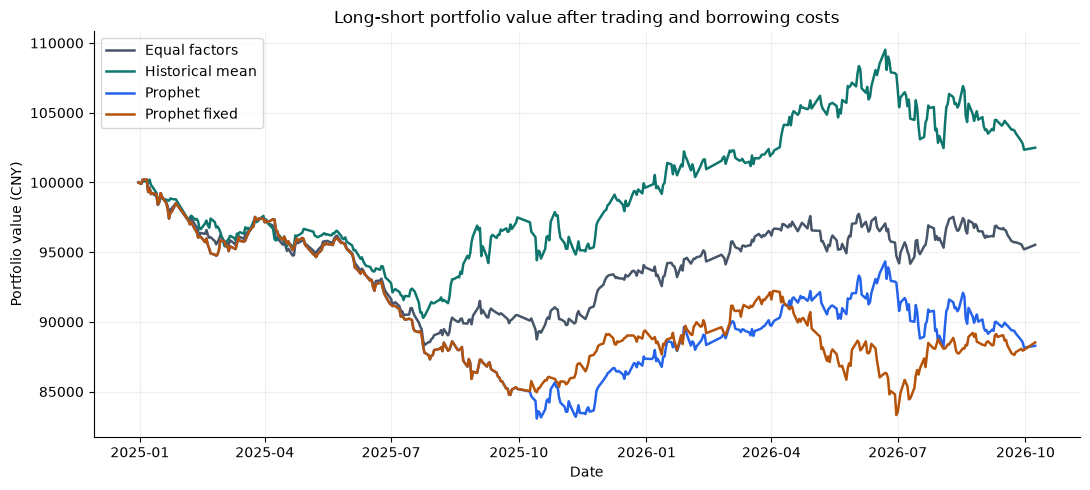

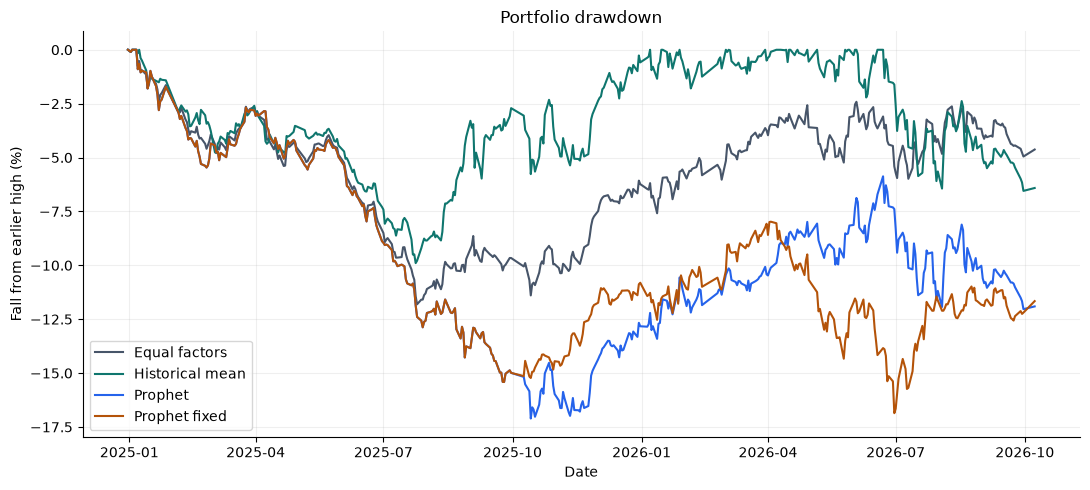

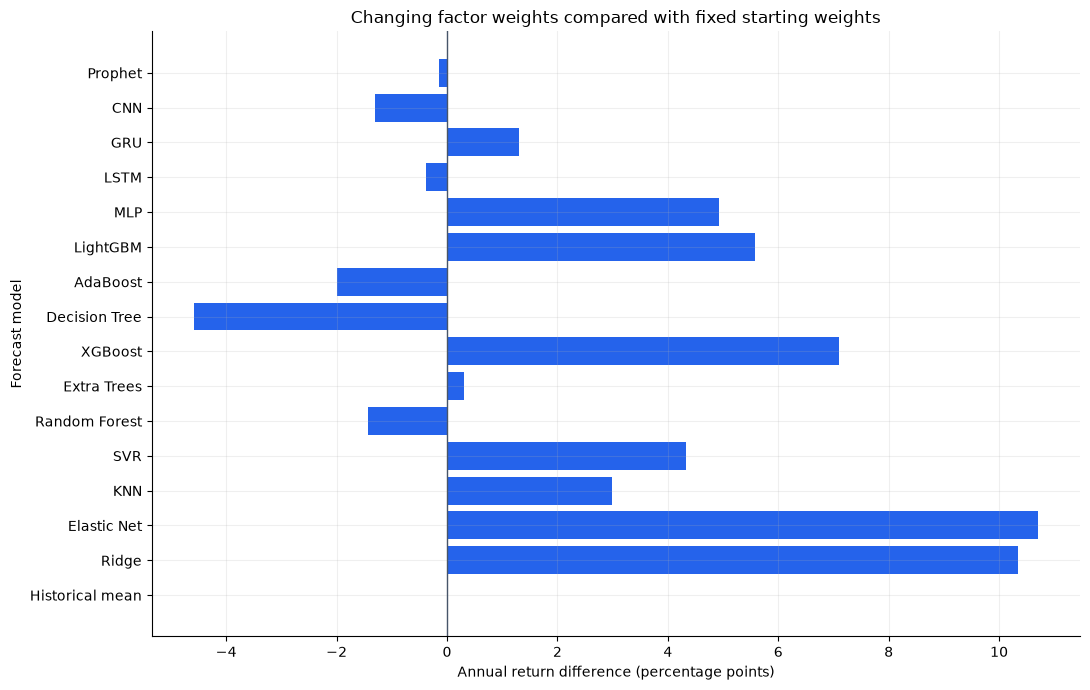

In [32]:
PLOT_COLORS = ['#475569', '#0f766e', '#2563eb', '#b45309']
PLOT_SIZE = (11, 5)

figure, axis = plt.subplots(figsize=PLOT_SIZE)
for chart_number, strategy in enumerate(comparison_names):
    axis.plot(portfolio_values.index, portfolio_values[strategy], label=strategy, color=PLOT_COLORS[chart_number], linewidth=1.8)
axis.set_title('Long-short portfolio value after trading and borrowing costs')
axis.set_xlabel('Date')
axis.set_ylabel('Portfolio value (CNY)')
axis.grid(alpha=0.2)
axis.legend()
figure.tight_layout()
figure.savefig(RESULTS / 'portfolio_values.png', dpi=160)
plt.show()

figure, axis = plt.subplots(figsize=PLOT_SIZE)
for chart_number, strategy in enumerate(comparison_names):
    series = portfolio_values[strategy]
    drawdowns = (series / series.cummax() - 1) * 100
    axis.plot(series.index, drawdowns, label=strategy, color=PLOT_COLORS[chart_number], linewidth=1.5)
axis.set_title('Portfolio drawdown')
axis.set_xlabel('Date')
axis.set_ylabel('Fall from earlier high (%)')
axis.grid(alpha=0.2)
axis.legend()
figure.tight_layout()
figure.savefig(RESULTS / 'drawdowns.png', dpi=160)
plt.show()

figure, axis = plt.subplots(figsize=(11, 7))
plot_table = dynamic_vs_fixed.set_index('model').reindex(MODEL_NAMES)
axis.barh(plot_table.index, plot_table.annual_return_gap_vs_fixed_pp, color='#2563eb')
axis.axvline(0, color='#475569', linewidth=1)
axis.set_title('Changing factor weights compared with fixed starting weights')
axis.set_xlabel('Annual return difference (percentage points)')
axis.set_ylabel('Forecast model')
axis.grid(axis='x', alpha=0.2)
figure.tight_layout()
figure.savefig(RESULTS / 'dynamic_vs_fixed.png', dpi=160)
plt.show()


The charts show the value and drawdown of the selected model and its controls. The last chart includes every model and its fixed starting weights. GRU, Ridge, Elastic Net, KNN, SVR, Extra Trees, XGBoost, LightGBM and MLP returned more than their own fixed controls. The historical-mean forecasts kept the same factor order in all 21 months, so changing and fixed weights gave the same result. This comparison shows why we check the starting weights as well as equal factor weights.

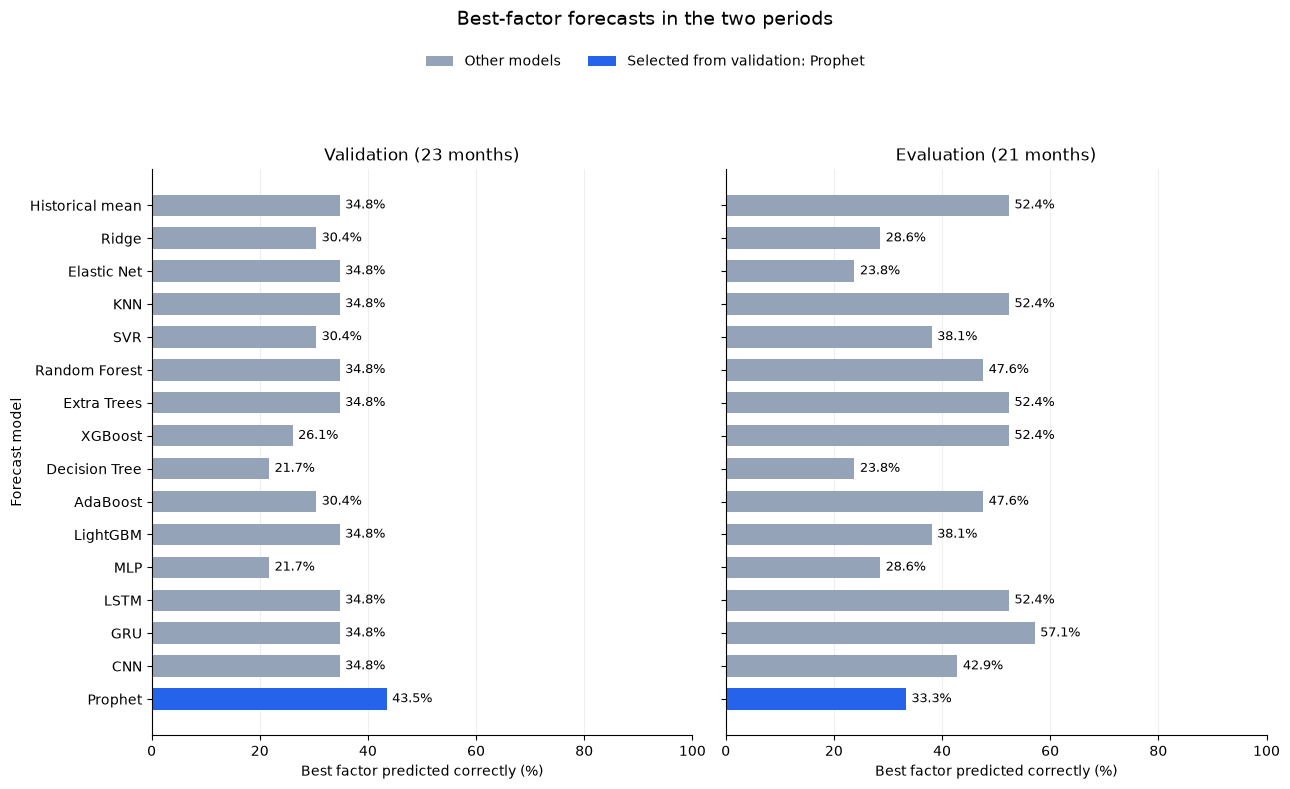

In [33]:
MODEL_ORDER = ['Historical mean', 'Ridge', 'Elastic Net', 'KNN', 'SVR', 'Random Forest', 'Extra Trees', 'XGBoost', 'Decision Tree', 'AdaBoost', 'LightGBM', 'MLP', 'LSTM', 'GRU', 'CNN', 'Prophet']
SELECTED_COLOR = '#2563eb'
OTHER_COLOR = '#94a3b8'

metrics_for_chart = pd.read_csv(RESULTS / 'forecast_metrics.csv')
selection_for_chart = pd.read_csv(RESULTS / 'model_selection.csv')
selected_rows = selection_for_chart.loc[selection_for_chart.selected.astype(str).str.lower().eq('true')]
if len(selected_rows) != 1:
    raise ValueError('The chart needs one model selected from validation.')
selected_name = str(selected_rows.iloc[0].model)

figure, axes = plt.subplots(1, 2, figsize=(13, 8), sharey=True, sharex=True)
for axis, split in zip(axes, ['validation', 'evaluation']):
    chart_data = metrics_for_chart.loc[metrics_for_chart.split.eq(split)].set_index('model').reindex(MODEL_ORDER)
    if chart_data.best_factor_hit_rate_pct.isna().any() or chart_data.index.duplicated().any():
        raise ValueError('A model result is missing or repeated in the chart.')
    positions = np.arange(len(MODEL_ORDER))
    values = chart_data.best_factor_hit_rate_pct.to_numpy()
    axis.barh(positions, values, color=OTHER_COLOR, height=0.65, label='Other models')
    selected_position = MODEL_ORDER.index(selected_name)
    axis.barh(selected_position, values[selected_position], color=SELECTED_COLOR, height=0.65, label='Selected from validation: ' + selected_name)
    for position, value in zip(positions, values):
        axis.text(min(value + 1, 98), position, f'{value:.1f}%', va='center', ha='left' if value < 95 else 'right', fontsize=9)
    axis.set_yticks(positions, MODEL_ORDER)
    axis.set_xlim(0, 100)
    axis.set_xticks(np.arange(0, 101, 20))
    axis.set_title(split.capitalize() + ' (' + str(int(chart_data.months.iloc[0])) + ' months)')
    axis.set_xlabel('Best factor predicted correctly (%)')
    axis.grid(axis='x', alpha=0.2)
    axis.grid(axis='y', visible=False)
    axis.set_axisbelow(True)
axes[0].invert_yaxis()
axes[0].set_ylabel('Forecast model')
handles, labels = axes[0].get_legend_handles_labels()
figure.suptitle('Best-factor forecasts in the two periods', fontsize=14)
figure.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.94), ncol=2, frameon=False)
figure.tight_layout(rect=(0, 0, 1, 0.87))
figure.savefig(RESULTS / 'factor_forecast_hit_rates.png', dpi=160, bbox_inches='tight')
plt.show()


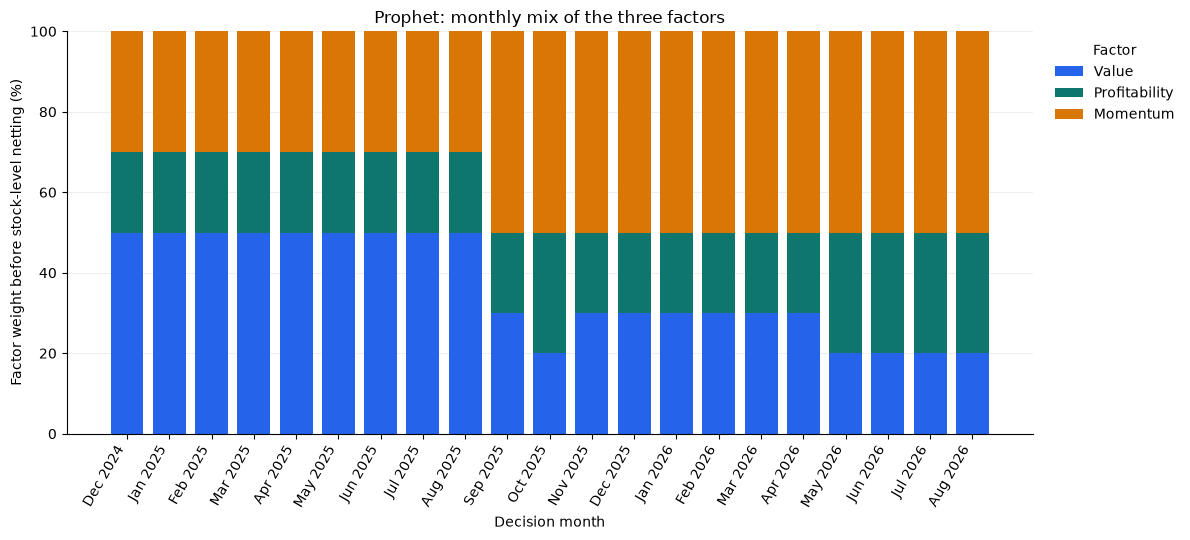

In [34]:
FACTOR_ORDER = ['Value', 'Profitability', 'Momentum']
FACTOR_COLORS = ['#2563eb', '#0f766e', '#d97706']

weights_for_chart = pd.read_csv(RESULTS / 'factor_weights.csv', parse_dates=['signal'])
selection_for_chart = pd.read_csv(RESULTS / 'model_selection.csv')
selected_rows = selection_for_chart.loc[selection_for_chart.selected.astype(str).str.lower().eq('true')]
if len(selected_rows) != 1:
    raise ValueError('The chart needs one model selected from validation.')
selected_name = str(selected_rows.iloc[0].model)
weights_for_chart = weights_for_chart.loc[weights_for_chart.strategy.eq(selected_name)].sort_values('signal').set_index('signal')
if weights_for_chart.empty or weights_for_chart.index.duplicated().any():
    raise ValueError('The selected model weights are missing or repeated.')
if not np.allclose(weights_for_chart[FACTOR_ORDER].sum(axis=1), 1):
    raise ValueError('The three factor weights must add to one.')

figure, axis = plt.subplots(figsize=(12, 5.5))
positions = np.arange(len(weights_for_chart))
bottom = np.zeros(len(weights_for_chart))
for factor, color in zip(FACTOR_ORDER, FACTOR_COLORS):
    values = weights_for_chart[factor].to_numpy() * 100
    axis.bar(positions, values, bottom=bottom, label=factor, color=color, width=0.78)
    bottom += values
axis.set_xticks(positions, weights_for_chart.index.strftime('%b %Y'), rotation=60, ha='right')
axis.set_ylim(0, 100)
axis.set_yticks(np.arange(0, 101, 20))
axis.set_title(selected_name + ': monthly mix of the three factors')
axis.set_xlabel('Decision month')
axis.set_ylabel('Factor weight before stock-level netting (%)')
axis.grid(axis='y', alpha=0.2)
axis.grid(axis='x', visible=False)
axis.set_axisbelow(True)
axis.legend(title='Factor', bbox_to_anchor=(1.01, 1), loc='upper left', frameon=False)
figure.tight_layout()
figure.savefig(RESULTS / 'selected_model_factor_weights.png', dpi=160, bbox_inches='tight')
plt.show()


Prophet started with 50% in Value, 20% in Profitability and 30% in Momentum. Its mix differed from these starting weights in 12 of the 21 months. It changed from the previous month's mix four times. These are factor weights before opposite stock positions cancel. The stock weights and costs are recorded separately.

We find that the results depend on both the model and the rule used to choose it. Several models earned more than equal factor weights. XGBoost had the highest return in the later period, while GRU found the best factor most often. Our earlier selection rule chose Prophet, and this portfolio earned less than equal factors. So this test shows useful differences between models, but it does not show an improvement from our reported model-selection rule. We report these results together so the forecast scores do not hide the portfolio result.

Our saved prices run from 5 January 2015 to 16 October 2026. Some companies listed later. Our first usable factor decision is 31 July 2018 and the first trade is 1 August 2018. We only use a company after its required data becomes available. Our validation covers 23 completed monthly periods from 3 January 2023 to 2 December 2024. The later comparison covers 21 periods from 2 January 2025 to 8 October 2026. The end of this comparison is the last completed holding period in these files.

We use adjusted closes to calculate price changes and raw A-share prices to calculate company value. Annual accounts enter after both their saved announcement date and 30 June of the following year. We use share counts only after their saved effective and available dates. These rules keep later announcements out of earlier decisions. The saved accounts can still include revisions, and we selected the company list today. We therefore describe the results as a test on this selected group.

Short positions are a research assumption. We include a borrowing charge, but the saved files do not tell us whether each stock could have been borrowed at each date. We also assume a trade can be made at the next observed closing price when volume is positive. Price limits, loan recalls and market impact are not simulated.

References

French, Kenneth R. Description of Fama/French 5 Factors (2 x 3). Dartmouth College, Data Library. We use the idea of a high-minus-low factor return. Our company group, signals and equal stock weights are different from the published Fama-French factors.

Shu, Yizhan, and John M. Mulvey. Dynamic Factor Allocation Leveraging Regime-Switching Signals. The Journal of Portfolio Management, vol. 51, no. 3, 2025, pp. 50–72. doi:10.3905/jpm.2024.1.649. Their study supports the research question about changing factor allocations. We use a different forecasting method and market.

Scikit-learn Developers. Cross-Validation: Evaluating Estimator Performance. Scikit-learn User Guide, section on time series.

Shenzhen Stock Exchange. Margin Trading and Securities Lending. Trading Services. This explains why actual short positions also depend on lending rules and available shares.